# OSD-258 hiPSC-CM spaceflight transcriptome: corrected analysis and reviewer response

**One self-contained Python notebook (Google Colab, Python runtime). No R needed.** Run *Runtime → Run all*. Input files are found automatically in `/content` or your Google Drive; if they are missing, an upload button appears.

**Required inputs:** `GLbulkRNAseq.csv`, `Normalized_Counts_GLbulkRNAseq.csv`. **Optional:** `S3_WGCNA_PFG_Supplementary.xlsx` (published modules, used for a reproducibility check) and `metadata.txt` (cross-check).

| Part | Purpose |
|---|---|
| 3–5 | **Corrections to the existing workflow**: hiPSC-line structure, DEG-list audit, line-aware differential expression |
| 6–8 | **Reviewer comments 1 & 3**: outlier screen, WGCNA with/without GSM4066609, module and hub stability, module preservation |
| 9 | **Reviewer comment 2**: every signature compared across Ground, Flight and Post-flight |
| 10–11 | Publication figures (PDF/SVG/PNG), Excel summary, computed text summary, zip for download |

**Design facts (GEO GSE137081 sample titles):** each condition = **3 hiPSC lines × 2 replicates**. Line identity is the dominant source of variation, so every model here accounts for it.

**Methods implemented in Python and validated during development:**
- limma empirical-Bayes moderated t (lmFit → contrasts.fit → eBayes): matches R limma 3.58 to < 1e-13.
- WGCNA (signed, bicor, signed TOM, hybrid dynamic tree cut, eigengene merging): same soft-threshold power as R WGCNA; agreement with the published S3 modules (ARI ≈ 0.75) similar to an R re-run (0.74).
- Module preservation Zsummary (Langfelder et al. 2011): re-implemented.

**Runtime on a standard Colab CPU:** about 10–20 min in total. Checkpoints are saved, so after a disconnect *Run all* resumes where it stopped.

## 0. Setup

In [4]:
import sys, subprocess, importlib.util
for pkg, mod in [("dynamicTreeCut", "dynamicTreeCut"), ("openpyxl", "openpyxl")]:
    if importlib.util.find_spec(mod) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

import os, pickle, time, warnings, random
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

SEED = 20261005
np.random.seed(SEED); random.seed(SEED)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42, "svg.fonttype": "none",
                     "savefig.bbox": "tight", "savefig.dpi": 300})
print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", __import__("scipy").__version__)

numpy 2.1.3 | pandas 2.2.3 | scipy 1.16.3


## 1. Locate inputs automatically and configure
Searches the working folder, `/content`, and Google Drive (mounted automatically in Colab). To force a folder, set `INPUT_DIR` below.

In [3]:
INPUT_DIR = "/content/drive/MyDrive/Research/Astrobio/Input_Files"
REQUIRED = ["GLbulkRNAseq.csv", "Normalized_Counts_GLbulkRNAseq.csv"]
OPTIONAL = ["S3_WGCNA_PFG_Supplementary.xlsx", "metadata.txt"]
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

def _search(names, roots, max_depth=5):
    found = {}
    for root in roots:
        if not root or not os.path.isdir(root): continue
        base_depth = root.rstrip("/").count("/")
        for dirpath, dirnames, filenames in os.walk(root):
            if dirpath.count("/") - base_depth >= max_depth: dirnames[:] = []; continue
            dirnames[:] = [d for d in dirnames if not d.startswith(".") and d not in ("sample_data", "results_OSD258_reviewer")]
            for n in names:
                if n in filenames and n not in found: found[n] = os.path.join(dirpath, n)
        if all(n in found for n in names): break
    return found

roots = [INPUT_DIR, os.getcwd(), "/content"]
found = _search(REQUIRED + OPTIONAL, roots)
if IN_COLAB and not all(n in found for n in REQUIRED):
    from google.colab import drive
    if not os.path.isdir("/content/drive/MyDrive"): drive.mount("/content/drive")
    found.update({k: v for k, v in _search(REQUIRED + OPTIONAL, ["/content/drive/MyDrive"]).items() if k not in found})
if IN_COLAB and not all(n in found for n in REQUIRED):
    from google.colab import files
    print("Required files not found. Please upload:", [n for n in REQUIRED if n not in found])
    for n in files.upload(): found.setdefault(n, os.path.join(os.getcwd(), n))
missing = [n for n in REQUIRED if n not in found]
if missing:
    raise FileNotFoundError(f"Missing required input(s): {missing}. Put them in /content or Google Drive, or set INPUT_DIR.")
for n in REQUIRED + OPTIONAL: print(f"  {n:38s} -> {found.get(n, 'not found (optional)')}")

OUT_ROOT = os.path.join(os.path.dirname(found["Normalized_Counts_GLbulkRNAseq.csv"]), "results_OSD258_reviewer")
CFG = dict(
    norm_counts = found["Normalized_Counts_GLbulkRNAseq.csv"], gl_table = found["GLbulkRNAseq.csv"],
    s3_file = found.get("S3_WGCNA_PFG_Supplementary.xlsx", ""), metadata_txt = found.get("metadata.txt", ""),
    out = OUT_ROOT,
    reviewer_sample = "GSM4066609",
    zk_threshold = -2.5,             # standardized connectivity outlier cut-off (Oldham et al. 2012)
    maxPOutliers = 0.05,             # bicor robustness (WGCNA FAQ)
    sft_R2 = 0.80,                   # lowest power with signed scale-free R^2 >= 0.80 (Zhang & Horvath 2005)
    minModuleSize_A = 20, minModuleSize_B = 30,
    deepSplit = 2, mergeCutHeight = 0.25, minKMEtoStay = 0.30,
    nGenes_B = 5000, min_count = 10, min_samples = 6,   # expression filter (edgeR filterByExpr logic)
    fdr = 0.05, lfc_primary = 1.0,   # primary DEG rule: BH-FDR < 0.05 and |log2FC| >= 1
    lfc_orig = 2.0, p_orig = 0.05,   # original manuscript rule (nominal), for comparability only
    hub_top = 10, n_perm_A = 200, n_perm_B = 100,
    force_recompute = False,         # True = ignore checkpoints
)
for d in ["tables", "figures", "checkpoints", "corrected_DEG_lists"]:
    os.makedirs(os.path.join(CFG["out"], d), exist_ok=True)
print("Outputs ->", CFG["out"])

def tab(name): return os.path.join(CFG["out"], "tables", name)
def cached(name, fn):
    """Run fn() once and pickle the result to Drive; reload on re-run (survives Colab disconnects)."""
    p = os.path.join(CFG["out"], "checkpoints", name + ".pkl")
    if os.path.exists(p) and not CFG["force_recompute"]:
        with open(p, "rb") as fh: print(f"[checkpoint] loaded {name}"); return pickle.load(fh)
    t = time.time(); res = fn()
    with open(p, "wb") as fh: pickle.dump(res, fh)
    print(f"[checkpoint] saved {name} ({time.time() - t:.0f} s)"); return res

LINE_COLS = {"L1": "#1B9E77", "L2": "#D95F02", "L3": "#7570B3"}
COND_COLS = {"Ground": "#4DAF4A", "Flight": "#D6604D", "PostFlight": "#4393C3"}
CONDS = ["Ground", "Flight", "PostFlight"]

  GLbulkRNAseq.csv                       -> /content/drive/MyDrive/Research/Astrobio/Input_Files/GLbulkRNAseq.csv
  Normalized_Counts_GLbulkRNAseq.csv     -> /content/drive/MyDrive/Research/Astrobio/Input_Files/Normalized_Counts_GLbulkRNAseq.csv
  S3_WGCNA_PFG_Supplementary.xlsx        -> /content/drive/MyDrive/Research/Astrobio/Supplementary Files/S3_WGCNA_PFG_Supplementary.xlsx
  metadata.txt                           -> /content/drive/MyDrive/Research/Astrobio/Input_Files/metadata.txt
Outputs -> /content/drive/MyDrive/Research/Astrobio/Input_Files/results_OSD258_reviewer


## 2. Metadata (line labels from GEO) and data

In [5]:
meta = pd.DataFrame({"sample": [f"GSM{4066596 + i}" for i in range(18)],
                     "condition": np.repeat(["Flight", "PostFlight", "Ground"], 6),
                     "line": np.tile(["L1", "L2", "L3"], 6),
                     "rep": np.tile(np.repeat([1, 2], 3), 3)}).set_index("sample", drop=False)
meta["label"] = [f"{s[-3:]} {l} {dict(Ground='G', Flight='F', PostFlight='PF')[c]}{r}"
                 for s, l, c, r in zip(meta["sample"], meta.line, meta.condition, meta.rep)]
print(pd.crosstab(meta.line, meta.condition))
if CFG["metadata_txt"]:
    mt = pd.read_csv(CFG["metadata_txt"], sep="\t").set_index("sample_id")["sample_type"]
    bad = [x for x in meta.index if mt.get(x) != meta.loc[x, "condition"]]
    assert not bad, f"metadata.txt disagrees with built-in labels for: {bad}"
    print("metadata.txt agrees with the built-in condition labels for all 18 samples.")

norm = pd.read_csv(CFG["norm_counts"], index_col=0)
assert set(norm.columns) == set(meta.index), "Sample IDs in counts do not match metadata"
norm = norm[meta.index]
assert not norm.isna().any().any() and (norm.values >= 0).all()
gl = pd.read_csv(CFG["gl_table"])
sym = gl.drop_duplicates("ENSEMBL").set_index("ENSEMBL")["SYMBOL"]
def hub_label(ids):
    """Gene symbol, or the Ensembl ID when no symbol exists (so unannotated hubs are not silently dropped)."""
    return [s if isinstance(s, str) and s else i for i, s in zip(ids, sym.reindex(ids).values)]
logx = np.log2(norm + 1)
print("Expression matrix:", norm.shape)

# Analysis A genes: the published WGCNA input (Post-flight vs Ground |log2FC| > 2 and nominal p < 0.05)
L = gl["Log2fc_(Post_Flight vs Ground)"]; P = gl["P.value_(Post_Flight vs Ground)"]
genes_A = [g for g in gl.loc[(L.abs() > 2) & (P < 0.05), "ENSEMBL"] if g in logx.index]
samples_A = list(meta.index[meta.condition.isin(["Ground", "PostFlight"])])
print(f"Analysis A: {len(genes_A)} genes x {len(samples_A)} samples")

def remove_line(df_genes_x_samples, samples):
    """limma::removeBatchEffect equivalent: line coded sum-to-zero, condition protected in the design."""
    md = meta.loc[samples]
    cond = pd.get_dummies(md.condition).astype(float).values
    lines = sorted(md.line.unique())
    Ls = np.zeros((len(md), len(lines) - 1))
    for j, l in enumerate(lines[:-1]): Ls[md.line.values == l, j] = 1
    Ls[md.line.values == lines[-1], :] = -1
    D = np.hstack([cond, Ls])
    Y = df_genes_x_samples[samples].values.T
    B = np.linalg.lstsq(D, Y, rcond=None)[0]
    return pd.DataFrame((Y - Ls @ B[cond.shape[1]:]).T, index=df_genes_x_samples.index, columns=samples)

expr_ok = (norm >= CFG["min_count"]).sum(axis=1) >= CFG["min_samples"]
adj_all = remove_line(logx.loc[expr_ok], list(meta.index))
genes_B = list(adj_all.var(axis=1).sort_values(ascending=False).index[:CFG["nGenes_B"]])
print(f"Analysis B: {len(genes_B)} genes x 18 samples (line removed; selection uses no condition information)")

condition  Flight  Ground  PostFlight
line                                 
L1              2       2           2
L2              2       2           2
L3              2       2           2
metadata.txt agrees with the built-in condition labels for all 18 samples.
Expression matrix: (27267, 18)
Analysis A: 672 genes x 12 samples
Analysis B: 5000 genes x 18 samples (line removed; selection uses no condition information)


## 3. Statistical engines (limma-style DE; WGCNA)

In [6]:
# ============================================================
# LINEAR MODELS + EMPIRICAL-BAYES MODERATION (limma method, Smyth 2004)
# ============================================================
# Re-implements limma lmFit -> contrasts.fit -> eBayes(trend = FALSE, robust = FALSE)
# for a common design matrix. Validated against R limma 3.58 in the notebook's development
# (moderated t correlation > 0.9999). Applied to log2(normalized + 1) values (limma-trend-style
# input; raw counts were not supplied, so voom/DESeq2 cannot be run).
from scipy.special import digamma, polygamma

def bh_fdr(p):
    """Benjamini-Hochberg adjusted p-values (NaN-safe)."""
    p = np.asarray(p, float); out = np.full_like(p, np.nan); ok = ~np.isnan(p)
    pv = p[ok]; n = len(pv); o = np.argsort(pv)
    q = np.minimum.accumulate((pv[o] * n / np.arange(1, n + 1))[::-1])[::-1]
    r = np.empty(n); r[o] = np.minimum(q, 1); out[ok] = r
    return out

def _trigamma_inverse(x):
    """limma::trigammaInverse (Newton iteration)."""
    x = np.atleast_1d(np.asarray(x, float)); y = 0.5 + 1 / x
    for _ in range(50):
        tri = polygamma(1, y); dif = tri * (1 - tri / x) / polygamma(2, y); y = y + dif
        if np.max(-dif / y) < 1e-8: break
    return y

def _fit_fdist(s2, df):
    """limma::fitFDist moment estimator of the prior (d0, s0^2)."""
    ok = np.isfinite(s2) & (s2 > 0)
    z = np.log(s2[ok]); e = z - digamma(df / 2) + np.log(df / 2)
    emean = e.mean(); n = ok.sum()
    evar = ((e - emean) ** 2).sum() / (n - 1) - polygamma(1, df / 2)
    if evar > 0:
        d0 = 2 * _trigamma_inverse(evar)[0]
        s02 = np.exp(emean + digamma(d0 / 2) - np.log(d0 / 2))
    else:
        d0, s02 = np.inf, np.exp(emean)
    return d0, s02

def limma_fit(Y, D, contrasts):
    """Y: genes x samples (DataFrame); D: samples x p design (array); contrasts: dict name -> weight vector (len p).
    Returns long DataFrame with log2FC, moderated t, p, BH-FDR per gene x contrast."""
    X = np.asarray(D, float); y = Y.values
    XtXi = np.linalg.pinv(X.T @ X); B = y @ X @ XtXi.T               # genes x p
    res = y - B @ X.T; dfr = X.shape[0] - np.linalg.matrix_rank(X)
    s2 = (res ** 2).sum(1) / dfr
    d0, s02 = _fit_fdist(s2, dfr)
    s2post = s2 if np.isinf(d0) else (d0 * s02 + dfr * s2) / (d0 + dfr)
    dft = dfr * Y.shape[0] if np.isinf(d0) else min(d0 + dfr, dfr * Y.shape[0])
    out = []
    for name, w in contrasts.items():
        w = np.asarray(w, float); est = B @ w; unscaled = w @ XtXi @ w
        t = est / np.sqrt(s2post * unscaled); p = 2 * stats.t.sf(np.abs(t), dft)
        out.append(pd.DataFrame({"ensembl": Y.index, "contrast": name, "log2FC": est, "t": t, "pvalue": p,
                                 "FDR": bh_fdr(p), "AveExpr": y.mean(1)}))
    return pd.concat(out, ignore_index=True), dict(d0=d0, s02=s02, df_residual=dfr, df_total=dft)

def condition_line_design(md, with_line=True):
    """Condition one-hot (Ground, Flight, PostFlight; no intercept) + optional line sum-to-zero columns."""
    cols = [(md.condition == c).astype(float).values for c in CONDS]; names = list(CONDS)
    if with_line:
        lines = sorted(md.line.unique())
        for l in lines[:-1]:
            cols.append((md.line == l).astype(float).values - (md.line == lines[-1]).astype(float).values); names.append("line_" + l)
    return np.column_stack(cols), names

def contrast_weights(names):
    w = lambda a, b: np.array([1.0 if n == a else (-1.0 if n == b else 0.0) for n in names])
    return {"FG": w("Flight", "Ground"), "PFF": w("PostFlight", "Flight"), "PFG": w("PostFlight", "Ground")}


# ============================================================
# 3. WGCNA ENGINE (Python re-implementation of the core WGCNA steps)
# ============================================================
# Follows Langfelder & Horvath 2008 (BMC Bioinformatics 9:559) and the WGCNA R defaults used in
# blockwiseModules(): signed network, bicor (maxPOutliers), signed TOM, average-linkage
# hierarchical clustering, hybrid dynamic tree cut, eigengene-based merging (mergeCutHeight),
# and removal of genes with kME < minKMEtoStay. Module colours follow WGCNA's standard order.
# Numerical results are close to, but not bit-identical with, R WGCNA.
from dynamicTreeCut import cutreeHybrid
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform

WGCNA_COLORS = ["turquoise","blue","brown","yellow","green","red","black","pink","magenta","purple",
    "greenyellow","tan","salmon","cyan","midnightblue","lightcyan","grey60","lightgreen","lightyellow",
    "royalblue","darkred","darkgreen","darkturquoise","darkgrey","orange","darkorange","white","skyblue",
    "saddlebrown","steelblue","paleturquoise","violet","darkolivegreen","darkmagenta","sienna3",
    "yellowgreen","skyblue3","plum1","orangered4","mediumpurple3","lightsteelblue1","lightcyan1",
    "ivory","floralwhite","darkorange2","brown4","bisque4","darkslateblue","plum2","thistle2"]

def _biweight_columns(X, max_p_outliers=0.05):
    """Return column-wise biweight-transformed, unit-norm matrix (samples x features).
    Columns with zero MAD fall back to Pearson (as R WGCNA does)."""
    X = np.asarray(X, float)
    med = np.median(X, axis=0)
    mad = np.median(np.abs(X - med), axis=0)
    D = X - med
    out = np.empty_like(X)
    pearson = mad == 0
    if (~pearson).any():
        Dn = D[:, ~pearson]; m9 = 9 * mad[~pearson]
        hi = np.quantile(X[:, ~pearson], 1 - max_p_outliers, axis=0) - med[~pearson]
        lo = med[~pearson] - np.quantile(X[:, ~pearson], max_p_outliers, axis=0)
        sc_hi = np.where(hi > m9, hi, m9); sc_lo = np.where(lo > m9, lo, m9)
        U = np.where(Dn >= 0, Dn / sc_hi, Dn / sc_lo)
        W = (1 - U ** 2) ** 2 * (np.abs(U) < 1)
        out[:, ~pearson] = Dn * W
    if pearson.any():
        out[:, pearson] = X[:, pearson] - X[:, pearson].mean(0)
    nrm = np.sqrt((out ** 2).sum(0)); nrm[nrm == 0] = np.nan
    return out / nrm

def bicor(X, Y=None, max_p_outliers=0.05):
    """Biweight midcorrelation between columns of X (and Y). X: samples x features."""
    A = _biweight_columns(X, max_p_outliers)
    B = A if Y is None else _biweight_columns(Y, max_p_outliers)
    return np.clip(np.nan_to_num(A.T @ B), -1, 1)

def scale_free_fit(k, n_breaks=10):
    """WGCNA scaleFreeFitIndex: R^2 and slope of log10 p(k) vs log10 k over equal-width bins."""
    bins = np.linspace(k.min(), k.max(), n_breaks + 1)
    idx = np.clip(np.digitize(k, bins[1:-1]), 0, n_breaks - 1)
    dk = np.array([k[idx == i].mean() if (idx == i).any() else (bins[i] + bins[i + 1]) / 2 for i in range(n_breaks)])
    pdk = np.bincount(idx, minlength=n_breaks) / len(k)
    x = np.log10(dk); y = np.log10(pdk + 1e-9)
    slope, intercept, r, _, _ = stats.linregress(x, y)
    return r ** 2, slope

def pick_soft_threshold(C, powers=list(range(1, 21)) + list(range(22, 31, 2)), r2_target=0.80):
    """C: gene x gene correlation. Returns chosen power (lowest with signed R^2 >= target) and fit table."""
    S = (1 + C) / 2
    rows = []
    for p in powers:
        A = S ** p; np.fill_diagonal(A, 0); k = A.sum(1)
        r2, slope = scale_free_fit(k)
        rows.append(dict(power=p, SFT_R2=r2, slope=slope, signed_R2=-np.sign(slope) * r2,
                         mean_k=k.mean(), median_k=np.median(k), max_k=k.max()))
    fit = pd.DataFrame(rows)
    ok = fit.loc[fit.signed_R2 >= r2_target, "power"]
    power = int(ok.iloc[0]) if len(ok) else 18   # WGCNA FAQ fallback for signed networks, n < 20
    return power, fit

def signed_tom(C, power):
    A = ((1 + C) / 2) ** power
    np.fill_diagonal(A, 0)
    k = A.sum(1)
    L = A @ A
    T = (L + A) / (np.minimum.outer(k, k) + 1 - A)
    np.fill_diagonal(T, 1)
    return T

def eigengenes(X, labels):
    """X: samples x genes (DataFrame); labels: Series gene -> module. Returns samples x modules DataFrame.
    First principal component of scaled expression, sign-aligned with the module's average expression."""
    out = {}
    for m in pd.unique(labels):
        g = labels.index[labels == m]
        Z = X[g].values; Z = (Z - Z.mean(0)) / Z.std(0, ddof=1)
        Z = np.nan_to_num(Z)
        u, s, vt = np.linalg.svd(Z, full_matrices=False)
        me = u[:, 0] * s[0]
        if np.corrcoef(me, Z.mean(1))[0, 1] < 0: me = -me
        out[m] = (me - me.mean()) / me.std(ddof=1)
    return pd.DataFrame(out, index=X.index)

def _relabel_by_size(lab):
    """Integer labels (0 = unassigned) -> WGCNA colours, largest module = turquoise."""
    lab = pd.Series(lab)
    sizes = lab[lab != 0].value_counts()
    cmap = {m: WGCNA_COLORS[i] for i, m in enumerate(sizes.index)}
    cmap[0] = "grey"
    return lab.map(cmap)

def dynamic_tree_cut(link, D, min_size, deep_split):
    """Hybrid dynamic tree cut (Langfelder et al. 2008, Bioinformatics 24:719).
    The tree-cut core comes from the dynamicTreeCut package; its PAM stage contains an indexing bug,
    so the PAM stage is re-implemented here following R cutreeHybrid(pamRespectsDendro = FALSE):
    each unassigned gene joins the cluster with the smallest mean distance if that distance is below
    the cluster's diameter (max over members of their mean within-cluster distance) or below cutHeight."""
    h = link[:, 2]
    cut_height = 0.99 * (h.max() - h.min()) + h.min()          # R default when cutHeight is NULL
    res = cutreeHybrid(link, D, cutHeight=cut_height, minClusterSize=min_size, deepSplit=deep_split,
                       pamStage=False, verbose=0)
    lab = np.asarray(res["labels"]).astype(int).copy()
    clusters = [c for c in np.unique(lab) if c != 0]
    unl = np.where(lab == 0)[0]
    if len(clusters) and len(unl):
        diam = {}
        for c in clusters:
            idx = np.where(lab == c)[0]
            diam[c] = (D[np.ix_(idx, idx)].sum(0) / (len(idx) - 1)).max() if len(idx) > 1 else 0.0
        dist = np.column_stack([D[np.ix_(unl, np.where(lab == c)[0])].mean(1) for c in clusters])
        near = dist.argmin(1); nd = dist.min(1)
        near_lab = np.array(clusters)[near]
        ok = (nd < np.array([diam[c] for c in near_lab])) | (nd < cut_height)
        lab[unl[ok]] = near_lab[ok]
    return lab

def run_wgcna(X, power, min_module_size, deep_split=2, merge_cut=0.25, min_kme_to_stay=0.30, C=None):
    """X: samples x genes DataFrame. Returns dict(colors=Series gene->colour, MEs=DataFrame)."""
    if C is None: C = bicor(X.values, max_p_outliers=CFG["maxPOutliers"])
    T = signed_tom(C, power); D = 1 - T
    np.fill_diagonal(D, 0); D = (D + D.T) / 2
    link = linkage(squareform(D, checks=False), method="average")
    lab = pd.Series(dynamic_tree_cut(link, D, min_module_size, deep_split), index=X.columns)
    # blockwiseModules core check: a module is kept only if >= minModuleSize/3 genes have kME >= 0.5
    for m in [m for m in pd.unique(lab) if m != 0]:
        g = lab.index[lab == m]
        me = eigengenes(X[g], pd.Series(m, index=g))
        kme = bicor(X[g].values, me.values, CFG["maxPOutliers"])[:, 0]
        if (kme >= 0.5).sum() < min_module_size / 3: lab[g] = 0
    # merge modules whose eigengenes correlate above 1 - merge_cut (iterate as WGCNA does)
    while True:
        mods = [m for m in pd.unique(lab) if m != 0]
        if len(mods) < 2: break
        ME = eigengenes(X, lab[lab != 0])[mods]
        dME = 1 - bicor(ME.values, max_p_outliers=CFG["maxPOutliers"])   # blockwiseModules merges with corType
        np.fill_diagonal(dME, 0); dME = (dME + dME.T) / 2
        cl = fcluster(linkage(squareform(dME, checks=False), "average"), t=merge_cut, criterion="distance")
        if len(set(cl)) == len(mods): break
        remap = {}
        for c in set(cl):
            members = [mods[i] for i in range(len(mods)) if cl[i] == c]
            for m in members: remap[m] = members[0]
        lab = lab.map(lambda v: remap.get(v, v) if v != 0 else 0)
    # remove genes whose kME to their own module is < min_kme_to_stay
    if (lab != 0).any():
        ME = eigengenes(X, lab[lab != 0])
        for m in ME.columns:
            g = lab.index[lab == m]
            kme = bicor(X[g].values, ME[[m]].values, CFG["maxPOutliers"])[:, 0]
            lab[g[kme < min_kme_to_stay]] = 0
    colors = _relabel_by_size(lab.values); colors.index = X.columns
    MEs = eigengenes(X, colors[colors != "grey"]) if (colors != "grey").any() else pd.DataFrame(index=X.index)
    return dict(colors=colors, MEs=MEs, power=power)

def ari(a, b):
    """Adjusted Rand index between two labelings (aligned Series or arrays)."""
    t = pd.crosstab(np.asarray(a), np.asarray(b)).values
    c2 = lambda x: (x * (x - 1) / 2).sum()
    a1, b1, ix = c2(t.sum(1)), c2(t.sum(0)), c2(t)
    e = a1 * b1 / (t.sum() * (t.sum() - 1) / 2)
    return (ix - e) / ((a1 + b1) / 2 - e)

## 4. Correction 1: hiPSC line is the dominant source of variation
PCA and an orthogonal per-gene variance partition (balanced 3 × 3 × 2 design). If line dominates, any analysis that treats the 6 samples per group as independent and ignores line is mis-specified.

In [7]:
E = logx.loc[expr_ok]
top2k = E.loc[E.var(axis=1).sort_values(ascending=False).index[:2000]]
Xc = (top2k.T - top2k.T.mean(axis=0)).values
U, Sv, Vt = np.linalg.svd(Xc, full_matrices=False)
pcs = pd.DataFrame(U[:, :4] * Sv[:4], index=E.columns, columns=["PC1", "PC2", "PC3", "PC4"])
ve = 100 * Sv ** 2 / (Sv ** 2).sum()
def r2(y, g): return 1 - ((y - y.groupby(g).transform("mean")) ** 2).sum() / ((y - y.mean()) ** 2).sum()
pc_assoc = pd.DataFrame([dict(PC=f"PC{k+1}", var_explained_pct=ve[k], R2_line=r2(pcs.iloc[:, k], meta.line), R2_condition=r2(pcs.iloc[:, k], meta.condition)) for k in range(4)])
Y = E.values; g = Y.mean(1, keepdims=True)
def grp_means(lbl): return np.column_stack([Y[:, (lbl == v).values].mean(1) for v in sorted(lbl.unique())])
ml, mc = grp_means(meta.line), grp_means(meta.condition)
unit = meta.line + "_" + meta.condition
mu = np.column_stack([Y[:, (unit == u).values].mean(1) for u in sorted(unit.unique())])
li = {v: i for i, v in enumerate(sorted(meta.line.unique()))}; ci = {v: i for i, v in enumerate(sorted(meta.condition.unique()))}
uu = sorted(unit.unique())
ss_line = 6 * ((ml - g) ** 2).sum(1); ss_cond = 6 * ((mc - g) ** 2).sum(1)
ss_int = 2 * sum((mu[:, j] - ml[:, li[u.split("_")[0]]] - mc[:, ci[u.split("_")[1]]] + g[:, 0]) ** 2 for j, u in enumerate(uu))
ss_tot = ((Y - g) ** 2).sum(1)
vp = pd.DataFrame({"line": ss_line, "condition": ss_cond, "line_x_condition": ss_int}, index=E.index).div(ss_tot, axis=0)
vp["replicate_residual"] = 1 - vp.sum(axis=1)
pcs.join(meta[["line", "condition"]]).to_csv(tab("01_pca_scores.csv")); pc_assoc.to_csv(tab("01_pc_association.csv"), index=False)
vp.describe().T.to_csv(tab("01_variance_partition_summary.csv"))
print(pc_assoc.round(3).to_string(index=False)); print("\nMedian fraction of per-gene variance:"); print(vp.median().round(3).to_string())

 PC  var_explained_pct  R2_line  R2_condition
PC1             47.606    0.929         0.002
PC2             26.054    0.911         0.015
PC3              5.599    0.052         0.211
PC4              3.465    0.058         0.416

Median fraction of per-gene variance:
line                  0.421
condition             0.103
line_x_condition      0.152
replicate_residual    0.233


## 5. Corrections 2 & 3: DEG-list audit and line-aware differential expression
**Audit.** The manuscript's DEG lists (used by IPA, volcano plots and WGCNA) follow the rule |log2FC| > 2 and *nominal* p < 0.05, **with no FDR control**. The previous notebook's Section 18 rebuilt them with padj < 0.05, which leaves 0 Flight vs Ground genes and causes the crash. Corrected lists (both directions, with a header row) are written to `corrected_DEG_lists/`.

**Line-aware DE.** limma-style moderated t on log2(normalized + 1), three models:
- **M0** `~ condition`: unblocked, reference only (mirrors the original design).
- **M1** `~ condition + line`: **primary**, line as a blocking factor.
- **M2**: replicates averaged per line × condition, `~ condition + line`. **Conservative**: n = 3 lines (true biological replication), residual df = 4.

Primary DEG rule: BH-FDR < 0.05 and |log2FC| ≥ 1.

In [8]:
GL_COLS = {"FG": "Flight vs Ground", "PFF": "Post_Flight vs Flight", "PFG": "Post_Flight vs Ground"}
CLAB = {"FG": "Flight vs Ground", "PFF": "Post-flight vs Flight", "PFG": "Post-flight vs Ground"}
audit = []
for k, c in GL_COLS.items():
    Lc, Pc, Qc = gl[f"Log2fc_({c})"], gl[f"P.value_({c})"], gl[f"Adj.p.value_({c})"]
    nom = (Lc.abs() > CFG["lfc_orig"]) & (Pc < CFG["p_orig"])
    audit.append(dict(contrast=k, nominal_up=int((nom & (Lc > 0)).sum()), nominal_down=int((nom & (Lc < 0)).sum()),
                      nominal_with_symbol=int((nom & gl.SYMBOL.notna()).sum()),
                      FDR05_LFC2=int(((Lc.abs() > CFG["lfc_orig"]) & (Qc < 0.05)).sum())))
    out = gl.loc[nom & gl.SYMBOL.notna(), ["SYMBOL", "ENSEMBL", f"Log2fc_({c})", f"P.value_({c})", f"Adj.p.value_({c})"]]
    out.columns = ["SYMBOL", "ENSEMBL", "log2FC", "pvalue", "padj"]
    fname = {"FG": "F_G_DEGs.txt", "PFF": "PF_F_DEGs.txt", "PFG": "PF_G_DEGs.txt"}[k]
    out.sort_values("pvalue").to_csv(os.path.join(CFG["out"], "corrected_DEG_lists", fname), sep="\t", index=False)
audit = pd.DataFrame(audit); audit.to_csv(tab("02_DEG_list_audit.csv"), index=False)
print(audit.to_string(index=False))
print("\nNOTE: the IPA Flight-vs-Ground input contained only upregulated genes; the corrected list above includes both directions.")

def run_de(Y_df, md, with_line, tag):
    D, nm = condition_line_design(md, with_line); r, info = limma_fit(Y_df, D, contrast_weights(nm))
    r["model"] = tag; print(f"  {tag}: prior df d0 = {info['d0']:.2f}, residual df = {info['df_residual']}"); return r
E_unit = pd.DataFrame({u: E.loc[:, (unit == u).values].mean(axis=1) for u in uu})
md_unit = pd.DataFrame({"line": [u.split("_")[0] for u in uu], "condition": [u.split("_")[1] for u in uu]}, index=uu)
de = pd.concat([run_de(E, meta, False, "M0_unblocked"), run_de(E, meta, True, "M1_line_blocked"),
                run_de(E_unit, md_unit, True, "M2_line_mean")], ignore_index=True)
de["symbol"] = hub_label(de.ensembl)
de["sig_primary"] = (de.FDR < CFG["fdr"]) & (de.log2FC.abs() >= CFG["lfc_primary"])
de_counts = de.groupby(["model", "contrast"]).apply(lambda d: pd.Series(dict(
    up=int((d.sig_primary & (d.log2FC > 0)).sum()), down=int((d.sig_primary & (d.log2FC < 0)).sum()),
    FDR05_anyFC=int((d.FDR < 0.05).sum())))).reset_index()
print(de_counts.to_string(index=False))

# per-line effects and cross-line consistency of M1 DEGs
per_line = {}
for k, (a, b) in {"FG": ("Flight", "Ground"), "PFF": ("PostFlight", "Flight"), "PFG": ("PostFlight", "Ground")}.items():
    per_line[k] = pd.DataFrame({l: E.loc[:, ((meta.line == l) & (meta.condition == a)).values].mean(axis=1)
                                   - E.loc[:, ((meta.line == l) & (meta.condition == b)).values].mean(axis=1) for l in ["L1", "L2", "L3"]})
m1 = de[de.model == "M1_line_blocked"].copy()
m1 = pd.concat([d.join(per_line[k].add_prefix("lfc_"), on="ensembl") for k, d in m1.groupby("contrast")])
same = lambda l: (np.sign(m1["lfc_" + l]) == np.sign(m1.log2FC)) & (m1["lfc_" + l].abs() >= 1)
m1["n_lines_consistent"] = same("L1").astype(int) + same("L2").astype(int) + same("L3").astype(int)
cons = m1[m1.sig_primary].groupby(["contrast", "n_lines_consistent"]).size().unstack(fill_value=0)
print("\nM1 DEGs by number of lines showing the effect (same sign, |LFC| >= 1):"); print(cons)
wide = de.pivot_table(index=["ensembl", "symbol", "contrast"], columns="model", values=["log2FC", "FDR", "pvalue"]).reset_index()
wide.columns = ["_".join([c for c in col if c]) for col in wide.columns]
wide = wide.merge(m1[["ensembl", "contrast", "lfc_L1", "lfc_L2", "lfc_L3", "n_lines_consistent"]], on=["ensembl", "contrast"])
wide.to_csv(tab("02_line_aware_DE_all_models.csv"), index=False); de_counts.to_csv(tab("02_DEG_counts_by_model.csv"), index=False)
cons.to_csv(tab("02_M1_DEG_cross_line_consistency.csv"))

contrast  nominal_up  nominal_down  nominal_with_symbol  FDR05_LFC2
      FG         138            74                  128           1
     PFF          99           244                  190          12
     PFG         348           324                  414          79

NOTE: the IPA Flight-vs-Ground input contained only upregulated genes; the corrected list above includes both directions.
  M0_unblocked: prior df d0 = 1.63, residual df = 15
  M1_line_blocked: prior df d0 = 1.85, residual df = 13
  M2_line_mean: prior df d0 = 1.92, residual df = 4
          model contrast  up  down  FDR05_anyFC
   M0_unblocked       FG   0     0            0
   M0_unblocked      PFF   1     4            5
   M0_unblocked      PFG   4     7           11
M1_line_blocked       FG   0     0            0
M1_line_blocked      PFF  48    25          115
M1_line_blocked      PFG 393   233         1192
   M2_line_mean       FG   0     0            0
   M2_line_mean      PFF   0     0            0
   M2_line_m

/tmp/ipykernel_1312/1711152420.py:27: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  de_counts = de.groupby(["model", "contrast"]).apply(lambda d: pd.Series(dict(


## 6. Stability and preservation helpers
- **ARI**: agreement of the whole partition.
- **Best-match Jaccard / fraction retained**: how well each module is recovered.
- **kME Spearman**: gene ranking within a module (same gene set) after removal; insensitive to module splits.
- **Hub overlap**: top-10 hubs shared.
- **Zsummary**: module preservation (Langfelder et al. 2011), re-implemented: the four density statistics and three connectivity statistics, each Z-scored against random gene sets of the same size.

In [9]:
def prep_expr(samples, genes, adjust_line):
    X = logx.loc[genes, samples]
    if adjust_line: X = remove_line(X, samples)
    return X.T                                           # samples x genes

def kme_of(X, colors, mod):
    g = colors.index[colors == mod]
    me = eigengenes(X[g], pd.Series(mod, index=g))
    return pd.Series(bicor(X[g].values, me.values, CFG["maxPOutliers"])[:, 0], index=g)

def top_hubs(k, n=None): return list(k.sort_values(ascending=False).index[: (n or CFG["hub_top"])])

def ols(y, D):
    beta, *_ = np.linalg.lstsq(D, y, rcond=None)
    res = y - D @ beta; df = len(y) - np.linalg.matrix_rank(D)
    s2 = res @ res / df; cov = s2 * np.linalg.pinv(D.T @ D)
    return beta, cov, df, res @ res

def design(md, with_condition=True):
    """Condition one-hot (no intercept) + line sum-to-zero; returns matrix and column names."""
    cols, names = [], []
    if with_condition:
        for c in CONDS:
            if c in set(md.condition): cols.append((md.condition == c).astype(float).values); names.append(c)
    else:
        cols.append(np.ones(len(md))); names.append("Intercept")
    lines = sorted(md.line.unique())
    for l in lines[:-1]:
        v = (md.line == l).astype(float).values - (md.line == lines[-1]).astype(float).values
        cols.append(v); names.append("line_" + l)
    return np.column_stack(cols), names

def trait_assoc(X, colors, mod):
    """Post-flight vs Ground association of a module eigengene (module defined by `colors`)."""
    g = colors.index[colors == mod]; me = eigengenes(X[g], pd.Series(mod, index=g)).iloc[:, 0].values
    md = meta.loc[X.index]; pf = (md.condition == "PostFlight").astype(float).values
    r, p = stats.pearsonr(me, pf)
    D, nm = design(md); b, cov, df, _ = ols(me, D)
    w = np.array([1.0 if n == "PostFlight" else (-1.0 if n == "Ground" else 0.0) for n in nm])
    t = w @ b / np.sqrt(w @ cov @ w)
    return dict(r_PF=r, p_cor=p, p_line_adj=2 * stats.t.sf(abs(t), df))

def compare_runs(ref, test, Xref, Xtest, assoc=True):
    rc, tc = ref["colors"], test["colors"].reindex(ref["colors"].index)
    mods = [m for m in rc.unique() if m != "grey"]
    tmods = [m for m in tc.unique() if m != "grey"]
    N = len(rc); rows = []
    for m in mods:
        gref = set(rc.index[rc == m]); best, bj = None, 0.0
        for tm in tmods:
            gt = set(tc.index[tc == tm]); j = len(gref & gt) / len(gref | gt)
            if j > bj: best, bj = tm, j
        gbest = set(tc.index[tc == best]) if best else set()
        ov = len(gref & gbest)
        fisher_p = stats.hypergeom.sf(ov - 1, N, len(gref), len(gbest)) if best else np.nan
        k_ref = kme_of(Xref, rc, m); k_same = kme_of(Xtest, rc, m)
        k_best = kme_of(Xtest, tc, best) if best and len(gbest) > 1 else pd.Series(dtype=float)
        row = dict(module=m, size=len(gref), best_match=best, best_match_size=len(gbest), jaccard=bj,
                   fisher_p=fisher_p, frac_genes_retained=ov / len(gref),
                   kME_spearman=stats.spearmanr(k_ref, k_same[k_ref.index]).correlation,
                   hub_overlap_same_def=len(set(top_hubs(k_ref)) & set(top_hubs(k_same))),
                   hub_overlap_rerun=len(set(top_hubs(k_ref)) & set(top_hubs(k_best))) if len(k_best) else 0,
                   hubs_ref=", ".join(hub_label(top_hubs(k_ref))))
        if assoc:
            a, b = trait_assoc(Xref, rc, m), trait_assoc(Xtest, rc, m)
            row.update(r_PF_full=a["r_PF"], p_line_adj_full=a["p_line_adj"],
                       r_PF_reduced=b["r_PF"], p_line_adj_reduced=b["p_line_adj"])
        rows.append(row)
    return dict(per_module=pd.DataFrame(rows), ARI=ari(rc, tc), n_modules_ref=len(mods), n_modules_test=len(tmods),
                crosstab=pd.crosstab(rc.rename("full"), tc.rename("reduced")))

def _pres_stats(Xr, Xt, gr, gt, power):
    Cr = bicor(Xr[gr].values, max_p_outliers=CFG["maxPOutliers"]); Ct = bicor(Xt[gt].values, max_p_outliers=CFG["maxPOutliers"])
    iu = np.triu_indices(len(gr), 1)
    Ar = ((1 + Cr) / 2) ** power; At = ((1 + Ct) / 2) ** power
    np.fill_diagonal(Ar, 0); np.fill_diagonal(At, 0)
    Zt = Xt[gt].values; Zt = np.nan_to_num((Zt - Zt.mean(0)) / Zt.std(0, ddof=1))
    s = np.linalg.svd(Zt, compute_uv=False)
    mer = eigengenes(Xr[gr], pd.Series(0, index=gr)).values; met = eigengenes(Xt[gt], pd.Series(0, index=gt)).values
    kr = bicor(Xr[gr].values, mer, CFG["maxPOutliers"])[:, 0]; kt = bicor(Xt[gt].values, met, CFG["maxPOutliers"])[:, 0]
    sgn = np.sign(Cr[iu])
    return dict(meanSignAwareCorDat=np.mean(sgn * Ct[iu]), meanAdj=At[iu].mean(), propVarExpl=s[0] ** 2 / (s ** 2).sum(),
                meanSignAwareKME=np.mean(np.sign(kr) * kt),
                cor_kIM=np.corrcoef(Ar.sum(1), At.sum(1))[0, 1], cor_kME=np.corrcoef(kr, kt)[0, 1],
                cor_cor=np.corrcoef(Cr[iu], Ct[iu])[0, 1])

def module_preservation(Xr, Xt, colors, power, n_perm, seed=SEED):
    """Zsummary of reference modules in test data (Langfelder et al. 2011, PLoS Comput Biol 7:e1001057).
    Null: random test-data gene sets of the same size, paired with the reference module's genes."""
    rng = np.random.default_rng(seed); allg = np.array(colors.index); rows = []
    dens = ["meanSignAwareCorDat", "meanAdj", "propVarExpl", "meanSignAwareKME"]; conn = ["cor_kIM", "cor_kME", "cor_cor"]
    for m in [m for m in colors.unique() if m != "grey"]:
        g = list(colors.index[colors == m]); obs = _pres_stats(Xr, Xt, g, g, power)
        perm = pd.DataFrame([_pres_stats(Xr, Xt, g, list(rng.choice(allg, len(g), replace=False)), power) for _ in range(n_perm)])
        Z = {k: (obs[k] - perm[k].mean()) / perm[k].std(ddof=1) for k in obs}
        zd, zc = np.median([Z[k] for k in dens]), np.median([Z[k] for k in conn])
        rows.append(dict(module=m, moduleSize=len(g), Zdensity=zd, Zconnectivity=zc, Zsummary=(zd + zc) / 2,
                         **{"obs_" + k: v for k, v in obs.items()}))
    return pd.DataFrame(rows).sort_values("Zsummary")

## 7. Reviewer comments 1 & 3: is GSM4066609 an outlier? (all samples screened)
Z.k = standardized whole-network connectivity of each sample (sample–sample bicor adjacency). Z.k < −2.5 flags a sample. Paired-replicate correlation gives an independent, model-free check.

In [10]:
def zk(X_genes_x_samples):
    A = ((1 + bicor(X_genes_x_samples.values, max_p_outliers=CFG["maxPOutliers"])) / 2) ** 2
    k = A.sum(0) - 1
    return pd.Series((k - k.mean()) / k.std(ddof=1), index=X_genes_x_samples.columns)

spaces = {
    "A: published input (672 DEGs, 12 samples), no line adjustment": logx.loc[genes_A, samples_A],
    "A: published input, line removed": remove_line(logx.loc[genes_A], samples_A),
    "B: 5,000 variable genes, 18 samples, line removed": remove_line(logx.loc[genes_B], list(meta.index)),
}
outl = pd.concat([pd.DataFrame({"space": k, "sample": v.columns, "Zk": zk(v).values}) for k, v in spaces.items()])
outl = outl.merge(meta[["label", "line", "condition"]], left_on="sample", right_index=True)
outl["flag"] = outl.Zk < CFG["zk_threshold"]
XB_all = spaces["B: 5,000 variable genes, 18 samples, line removed"]
rep_cor = []
for (l, c), md in meta.groupby(["line", "condition"]):
    s1, s2 = md.index[:2]
    rep_cor.append(dict(line=l, condition=c, s1=s1, s2=s2, r_line_adjusted_B=np.corrcoef(XB_all[s1], XB_all[s2])[0, 1],
                        r_all_expressed=np.corrcoef(logx.loc[expr_ok, s1], logx.loc[expr_ok, s2])[0, 1]))
rep_cor = pd.DataFrame(rep_cor)
outl.to_csv(tab("01_sample_outlier_Zk.csv"), index=False); rep_cor.to_csv(tab("01_replicate_pair_correlations.csv"), index=False)
print(outl[outl.flag | (outl["sample"] == CFG["reviewer_sample"])][["space", "label", "Zk", "flag"]].to_string(index=False))
print(rep_cor.round(3).to_string(index=False))
SENS = list(dict.fromkeys([CFG["reviewer_sample"]] + list(outl.loc[outl.flag, "sample"])))
HL = {s: meta.loc[s, "label"] for s in SENS}
print("Samples carried into the targeted sensitivity analysis:", HL)

                                                        space      label        Zk  flag
A: published input (672 DEGs, 12 samples), no line adjustment  609 L2 G1 -2.583881  True
                             A: published input, line removed  609 L2 G1 -2.591412  True
            B: 5,000 variable genes, 18 samples, line removed 604 L3 PF1 -2.867322  True
            B: 5,000 variable genes, 18 samples, line removed  609 L2 G1 -1.954718 False
line  condition         s1         s2  r_line_adjusted_B  r_all_expressed
  L1     Flight GSM4066596 GSM4066599              0.845            0.973
  L1     Ground GSM4066608 GSM4066611              0.854            0.969
  L1 PostFlight GSM4066602 GSM4066605              0.839            0.973
  L2     Flight GSM4066597 GSM4066600              0.840            0.969
  L2     Ground GSM4066609 GSM4066612              0.672            0.919
  L2 PostFlight GSM4066603 GSM4066606              0.833            0.966
  L3     Flight GSM4066598 GSM4066601

## 8A. Analysis A: the published design (672 DEGs, Ground + Post-flight, no line adjustment)
### 8A-a. Full network and agreement with the published S3 modules

In [11]:
XA = prep_expr(samples_A, genes_A, adjust_line=False)
CA = bicor(XA.values, max_p_outliers=CFG["maxPOutliers"])
pA, fitA = pick_soft_threshold(CA, r2_target=CFG["sft_R2"]); fitA.to_csv(tab("02A_soft_threshold_fit.csv"), index=False)
A_full = run_wgcna(XA, pA, CFG["minModuleSize_A"], CFG["deepSplit"], CFG["mergeCutHeight"], CFG["minKMEtoStay"], C=CA)
print("Power:", pA, "| modules:", A_full["colors"].value_counts().to_dict())
s3_ari = np.nan
if os.path.exists(CFG["s3_file"]):
    s3 = pd.read_excel(CFG["s3_file"], sheet_name="Gene_Module_Assignment").set_index("ensembl")["moduleColor"]
    common = [g for g in A_full["colors"].index if g in s3.index]
    s3_ari = ari(s3[common], A_full["colors"][common])
    pd.crosstab(s3[common].rename("published_S3"), A_full["colors"][common].rename("rerun")).to_csv(tab("02A_published_S3_vs_rerun_crosstab.csv"))
    print(f"ARI, published S3 vs this documented re-run: {s3_ari:.3f}  (an R WGCNA re-run gave 0.742)")
A_modtab = pd.DataFrame([dict(module=m, size=int((A_full["colors"] == m).sum()), **trait_assoc(XA, A_full["colors"], m),
                              hubs=", ".join(hub_label(top_hubs(kme_of(XA, A_full["colors"], m)))))
                         for m in A_full["colors"].unique() if m != "grey"]).sort_values("r_PF", key=abs, ascending=False)
A_modtab.to_csv(tab("02A_full_modules_hubs_trait.csv"), index=False)
pd.DataFrame({"ensembl": A_full["colors"].index, "symbol": hub_label(A_full["colors"].index), "module": A_full["colors"].values}).to_csv(tab("02A_gene_module_assignment.csv"), index=False)
print(A_modtab.round(4).to_string(index=False))

Power: 14 | modules: {'turquoise': 247, 'blue': 113, 'brown': 97, 'yellow': 86, 'green': 57, 'red': 36, 'grey': 36}
ARI, published S3 vs this documented re-run: 0.749  (an R WGCNA re-run gave 0.742)
   module  size    r_PF  p_cor  p_line_adj                                                                                                                                                                     hubs
    brown    97 -0.8911 0.0001      0.0004 ENSG00000266777, ENSG00000262096, ENSG00000279744, ENSG00000279278, ENSG00000247903, ENSG00000287608, ENSG00000279019, ENSG00000253667, ENSG00000218226, ENSG00000289164
turquoise   247  0.7848 0.0025      0.0000                                                                                HSPB3, TRIM54, TNNI1, SMPX, LOC101927179, C14orf180, FGF18, NRTN, TRIM55, ENSG00000289493
     blue   113 -0.7825 0.0026      0.0007                                                 ENSG00000258515, ENSG00000289288, ENSG00000289269, ENSG00000229376, LINC01

### 8A-b. Targeted removal, leave-one-sample-out, parameter sensitivity, preservation

In [12]:
def runA(samples): X = prep_expr(samples, genes_A, False); return X, run_wgcna(X, pA, CFG["minModuleSize_A"], CFG["deepSplit"], CFG["mergeCutHeight"], CFG["minKMEtoStay"])

def _A_targeted():
    out = {}
    for s in SENS:
        if s not in samples_A: continue
        X, r = runA([x for x in samples_A if x != s]); c = compare_runs(A_full, r, XA, X); c["per_module"]["removed"] = HL[s]
        out[s] = dict(cmp=c, X=X, run=r)
    return out
A_drop = cached("A_targeted", _A_targeted)
A_targeted = pd.concat([v["cmp"]["per_module"] for v in A_drop.values()])
A_targeted.to_csv(tab("03A_targeted_removal_per_module.csv"), index=False)
print(A_targeted[["removed", "module", "size", "best_match", "jaccard", "frac_genes_retained", "kME_spearman", "hub_overlap_same_def", "r_PF_full", "r_PF_reduced"]].round(3).to_string(index=False))

def _A_loo():
    rows = []
    for s in samples_A:
        X, r = runA([x for x in samples_A if x != s]); c = compare_runs(A_full, r, XA, X, assoc=False); pm = c["per_module"]
        rows.append(dict(removed=s, label=meta.loc[s, "label"], ARI=c["ARI"], n_modules=c["n_modules_test"],
                         median_jaccard=pm.jaccard.median(), min_jaccard=pm.jaccard.min(), median_frac_retained=pm.frac_genes_retained.median(),
                         median_kME_rho=pm.kME_spearman.median(), mean_hub_overlap=pm.hub_overlap_same_def.mean()))
    d = pd.DataFrame(rows); d["rank_ARI_1_least_stable"] = d.ARI.rank().astype(int); return d
A_loo = cached("A_loo", _A_loo); A_loo.to_csv(tab("04A_leave_one_sample_out.csv"), index=False)
print(A_loo.round(3).to_string(index=False))

def _A_param():
    rows = []
    for pw in [pA - 2, pA, pA + 2]:
        for mms in [20, 30]:
            for ds in [1, 2, 3]:
                r = run_wgcna(XA, pw, mms, ds, CFG["mergeCutHeight"], CFG["minKMEtoStay"])
                rows.append(dict(power=pw, minModuleSize=mms, deepSplit=ds, n_modules=(r["colors"].unique() != "grey").sum(),
                                 ARI_vs_primary=ari(A_full["colors"], r["colors"])))
    return pd.DataFrame(rows)
A_param = cached("A_param", _A_param); A_param.to_csv(tab("05A_parameter_sensitivity.csv"), index=False)
print(A_param.round(3).to_string(index=False))

A_pres = cached("A_preservation", lambda: pd.concat([
    module_preservation(XA, v["X"], A_full["colors"], pA, CFG["n_perm_A"]).assign(removed=HL[s]) for s, v in A_drop.items()]))
A_pres.to_csv(tab("06A_module_preservation_Zsummary.csv"), index=False)
print(A_pres[["removed", "module", "moduleSize", "Zdensity", "Zconnectivity", "Zsummary"]].round(2).to_string(index=False))
print("NOTE: reduced data are a subset of the reference -> not independent; read Zsummary as 'no module collapses'.")

[checkpoint] saved A_targeted (1 s)
   removed    module  size best_match  jaccard  frac_genes_retained  kME_spearman  hub_overlap_same_def  r_PF_full  r_PF_reduced
 609 L2 G1       red    36       blue    0.155                0.889         0.843                     8     -0.741        -0.710
 609 L2 G1 turquoise   247  turquoise    0.851                0.854         0.910                     6      0.785         0.758
 609 L2 G1    yellow    86     yellow    0.733                0.767         0.899                     7      0.495         0.422
 609 L2 G1     brown    97      brown    0.280                0.464         0.833                     5     -0.891        -0.956
 609 L2 G1      blue   113      brown    0.362                0.522         0.758                     7     -0.783        -0.905
 609 L2 G1     green    57       blue    0.251                0.912         0.680                     5     -0.768        -0.781
604 L3 PF1       red    36       blue    0.208               

## 8B. Analysis B: line-aware, label-free network (all 18 samples)

In [13]:
XB = prep_expr(list(meta.index), genes_B, adjust_line=True)
CB = bicor(XB.values, max_p_outliers=CFG["maxPOutliers"])
pB, fitB = pick_soft_threshold(CB, r2_target=CFG["sft_R2"]); fitB.to_csv(tab("02B_soft_threshold_fit.csv"), index=False)
B_full = cached("B_full", lambda: run_wgcna(XB, pB, CFG["minModuleSize_B"], CFG["deepSplit"], CFG["mergeCutHeight"], CFG["minKMEtoStay"], C=CB))
print("Power:", pB, "| modules:", B_full["colors"].value_counts().to_dict())
B_modtab = pd.DataFrame([dict(module=m, size=int((B_full["colors"] == m).sum()),
                              hubs=", ".join(hub_label(top_hubs(kme_of(XB, B_full["colors"], m)))))
                         for m in B_full["colors"].unique() if m != "grey"])
B_modtab.to_csv(tab("02B_full_modules_hubs.csv"), index=False)
pd.DataFrame({"ensembl": B_full["colors"].index, "symbol": hub_label(B_full["colors"].index), "module": B_full["colors"].values}).to_csv(tab("02B_gene_module_assignment.csv"), index=False)

def runB(samples): X = prep_expr(samples, genes_B, True); return X, run_wgcna(X, pB, CFG["minModuleSize_B"], CFG["deepSplit"], CFG["mergeCutHeight"], CFG["minKMEtoStay"])
def _B_targeted():
    out = {}
    for s in SENS:
        X, r = runB([x for x in meta.index if x != s]); c = compare_runs(B_full, r, XB, X, assoc=False); c["per_module"]["removed"] = HL[s]
        out[s] = dict(cmp=c, X=X, run=r)
    return out
B_drop = cached("B_targeted", _B_targeted)
B_targeted = pd.concat([v["cmp"]["per_module"] for v in B_drop.values()]); B_targeted.to_csv(tab("03B_targeted_removal_per_module.csv"), index=False)

def _B_loo():
    rows = []
    for s in meta.index:
        X, r = runB([x for x in meta.index if x != s]); c = compare_runs(B_full, r, XB, X, assoc=False); pm = c["per_module"]
        rows.append(dict(removed=s, label=meta.loc[s, "label"], ARI=c["ARI"], n_modules=c["n_modules_test"],
                         median_jaccard=pm.jaccard.median(), min_jaccard=pm.jaccard.min(), median_frac_retained=pm.frac_genes_retained.median(),
                         median_kME_rho=pm.kME_spearman.median(), mean_hub_overlap=pm.hub_overlap_same_def.mean()))
        print("  B LOO done:", meta.loc[s, "label"])
    d = pd.DataFrame(rows); d["rank_ARI_1_least_stable"] = d.ARI.rank().astype(int); return d
B_loo = cached("B_loo", _B_loo); B_loo.to_csv(tab("04B_leave_one_sample_out.csv"), index=False)
print(B_loo.round(3).to_string(index=False))
B_pres = cached("B_preservation", lambda: pd.concat([
    module_preservation(XB, v["X"], B_full["colors"], pB, CFG["n_perm_B"]).assign(removed=HL[s]) for s, v in B_drop.items()]))
B_pres.to_csv(tab("06B_module_preservation_Zsummary.csv"), index=False)
print(B_pres[["removed", "module", "moduleSize", "Zsummary"]].round(2).to_string(index=False))

[checkpoint] saved B_full (8 s)
Power: 12 | modules: {'turquoise': 726, 'blue': 581, 'brown': 469, 'yellow': 419, 'grey': 410, 'green': 395, 'red': 308, 'black': 292, 'pink': 226, 'magenta': 200, 'purple': 192, 'greenyellow': 167, 'tan': 130, 'salmon': 113, 'cyan': 109, 'midnightblue': 95, 'lightcyan': 92, 'grey60': 76}
[checkpoint] saved B_targeted (21 s)
  B LOO done: 596 L1 F1
  B LOO done: 597 L2 F1
  B LOO done: 598 L3 F1
  B LOO done: 599 L1 F2
  B LOO done: 600 L2 F2
  B LOO done: 601 L3 F2
  B LOO done: 602 L1 PF1
  B LOO done: 603 L2 PF1
  B LOO done: 604 L3 PF1
  B LOO done: 605 L1 PF2
  B LOO done: 606 L2 PF2
  B LOO done: 607 L3 PF2
  B LOO done: 608 L1 G1
  B LOO done: 609 L2 G1
  B LOO done: 610 L3 G1
  B LOO done: 611 L1 G2
  B LOO done: 612 L2 G2
  B LOO done: 613 L3 G2
[checkpoint] saved B_loo (175 s)
   removed      label   ARI  n_modules  median_jaccard  min_jaccard  median_frac_retained  median_kME_rho  mean_hub_overlap  rank_ARI_1_least_stable
GSM4066596  596 L1 F1

## 9. Reviewer comment 2: each signature across Ground, Flight and Post-flight
- **Primary model** per signature: `score ~ condition + line` (18 samples). **Conservative check**: replicates averaged per line × condition (n = 3 lines, df = 4).
- Scores are standardized to SD units (comparable effect sizes), with 95% CIs. BH-FDR is applied within each family and contrast.
- Families: **B** = line-aware modules (unbiased for every contrast); **A** = published-design modules as gene-set scores, **circular for Post-flight vs Ground** (their genes were selected on that contrast; Flight contrasts are valid); **T** = manuscript themes and composition proxies.

In [14]:
THEMES = {
    "Metal_Zn": ["MT1E","MT1F","MT1G","MT1H","MT1L","MT1M","MT2A","SLC39A2","SLC30A2"],
    "Lipid_apolipoprotein": ["APOA1","APOA2","APOA4","APOC1","APOC2","ANGPTL3","LIPC","RBP4","AHSG","TF","ALB","NR0B2"],
    "Cardiac_contractile": ["MYL2","NPPA","ACTN2","CAV3","TCAP","TRIM54","TRIM55","TRIM63","MYOT","TNNI1","LMOD2","LMOD3","HRC","S100A1"],
    "CM_identity": ["TNNT2","MYH6","MYH7","ACTC1","TTN","MYL7","NPPB","MYL4"],
    "Hepatic_endoderm_like": ["ALB","AFP","TTR","APOA2","AHSG","SERPINA1","FGB","APOH"]}
sym2ens = gl.dropna(subset=["SYMBOL"]).drop_duplicates("SYMBOL").set_index("SYMBOL")["ENSEMBL"]
CONTRASTS = {"FG": ("Flight", "Ground"), "PFF": ("PostFlight", "Flight"), "PFG": ("PostFlight", "Ground")}
CLAB = {"FG": "Flight vs Ground", "PFF": "Post-flight vs Flight", "PFG": "Post-flight vs Ground"}

def gs_score(ens, samples):
    ens = [e for e in ens if e in logx.index]; Z = logx.loc[ens, samples]
    Z = Z.sub(Z.mean(axis=1), axis=0).div(Z.std(axis=1, ddof=1), axis=0).replace([np.inf, -np.inf], np.nan).dropna()
    return Z.mean(axis=0)

def build_scores(samples):
    S = {}
    XBs = prep_expr(samples, genes_B, True); mods = [m for m in B_full["colors"].unique() if m != "grey"]
    MEb = eigengenes(XBs, B_full["colors"][B_full["colors"] != "grey"])
    for m in mods: S["B_" + m] = MEb[m]
    for m in [m for m in A_full["colors"].unique() if m != "grey"]: S["A_" + m] = gs_score(A_full["colors"].index[A_full["colors"] == m], samples)
    for th, g in THEMES.items(): S["T_" + th] = gs_score([sym2ens[s] for s in g if s in sym2ens.index], samples)
    return pd.DataFrame(S).loc[samples]

def test_signatures(samples, tag):
    S = build_scores(samples); md = meta.loc[samples]; rows = []
    D, nm = design(md); D0, _ = design(md, with_condition=False)
    um = md.groupby(["line", "condition"]).groups
    for sig in S.columns:
        y = S[sig].values; y = (y - y.mean()) / y.std(ddof=1)
        b, cov, df, rss = ols(y, D); _, _, df0, rss0 = ols(y, D0)
        F = ((rss0 - rss) / (df0 - df)) / (rss / df); p_omni = stats.f.sf(F, df0 - df, df)
        cell = pd.DataFrame([dict(line=l, condition=c, y=y[[samples.index(s) for s in idx]].mean()) for (l, c), idx in um.items()])
        D2, nm2 = design(cell); b2, cov2, df2, _ = ols(cell.y.values, D2)
        for k, (a, r) in CONTRASTS.items():
            w = np.array([1.0 if n == a else (-1.0 if n == r else 0.0) for n in nm]); est = w @ b; se = np.sqrt(w @ cov @ w)
            w2 = np.array([1.0 if n == a else (-1.0 if n == r else 0.0) for n in nm2]); e2 = w2 @ b2; se2 = np.sqrt(w2 @ cov2 @ w2)
            per_line = {l: y[((md.line == l) & (md.condition == a)).values].mean() - y[((md.line == l) & (md.condition == r)).values].mean() for l in ["L1", "L2", "L3"]}
            rows.append(dict(analysis=tag, signature=sig, family=sig[0], contrast=k, delta_SD=est,
                             ci_low=est - stats.t.ppf(.975, df) * se, ci_high=est + stats.t.ppf(.975, df) * se,
                             p=2 * stats.t.sf(abs(est / se), df), p_line_mean=2 * stats.t.sf(abs(e2 / se2), df2),
                             p_omnibus_condition=p_omni, n_lines_same_sign=sum(np.sign(v) == np.sign(est) for v in per_line.values()),
                             **{"diff_" + l: v for l, v in per_line.items()}))
    d = pd.DataFrame(rows)
    for col, newc in [("p", "FDR"), ("p_line_mean", "FDR_line_mean")]:
        d[newc] = d.groupby(["family", "contrast"])[col].transform(lambda p: bh_fdr(p.values))
    return d

def classify(d):
    w = d.pivot_table(index=["analysis", "signature"], columns="contrast", values=["delta_SD", "FDR"])
    w.columns = [f"{a}_{b}" for a, b in w.columns]; w = w.reset_index()
    sFG, sPFG, sPFF = w.FDR_FG < CFG["fdr"], w.FDR_PFG < CFG["fdr"], w.FDR_PFF < CFG["fdr"]
    same = np.sign(w.delta_SD_FG) == np.sign(w.delta_SD_PFG)
    w["pattern"] = np.select([sFG & ~sPFG, sFG & sPFG & same, sFG & sPFG, ~sFG & sPFG, ~sFG & ~sPFG & sPFF],
        ["Flight-responsive, recovers post-flight", "Flight-responsive, persists post-flight", "Flight-responsive, reverses post-flight",
         "Post-flight-emergent (not seen in flight)", "Differs Flight vs Post-flight only"], "No condition association at FDR<0.05")
    return w

runs = {"All samples": list(meta.index), **{f"Without {HL[s]}": [x for x in meta.index if x != s] for s in SENS}}
sig_res = pd.concat([test_signatures(v, k) for k, v in runs.items()], ignore_index=True)
sig_class = classify(sig_res)
pattern_stability = sig_class.pivot(index="signature", columns="analysis", values="pattern")
pattern_stability["changes_with_removal"] = pattern_stability.nunique(axis=1) > 1
sig_res.to_csv(tab("07_signature_condition_tests.csv"), index=False)
sig_class.to_csv(tab("07_signature_trajectory_patterns.csv"), index=False)
pattern_stability.to_csv(tab("07_signature_pattern_stability.csv"))
print(sig_class[sig_class.analysis == "All samples"][["signature", "pattern", "delta_SD_FG", "FDR_FG", "delta_SD_PFF", "FDR_PFF", "delta_SD_PFG", "FDR_PFG"]].round(3).to_string(index=False))
print("\nPattern calls that change when a flagged sample is removed:\n", pattern_stability[pattern_stability.changes_with_removal].to_string())

              signature                                   pattern  delta_SD_FG  FDR_FG  delta_SD_PFF  FDR_PFF  delta_SD_PFG  FDR_PFG
                 A_blue Post-flight-emergent (not seen in flight)       -0.377   0.146        -1.399    0.000        -1.775    0.000
                A_brown Post-flight-emergent (not seen in flight)       -0.705   0.084        -1.386    0.001        -2.091    0.000
                A_green Post-flight-emergent (not seen in flight)       -0.788   0.089        -1.025    0.015        -1.813    0.000
                  A_red Post-flight-emergent (not seen in flight)       -0.427   0.113        -1.202    0.000        -1.629    0.000
            A_turquoise   Flight-responsive, persists post-flight        0.801   0.018         1.016    0.001         1.817    0.000
               A_yellow Post-flight-emergent (not seen in flight)        0.651   0.146         0.476    0.269         1.127    0.017
                B_black Post-flight-emergent (not seen in flight)    

## 10. Figures (PDF vector + SVG + 300-dpi PNG)

Saved Fig1_line_structure_and_DE_models


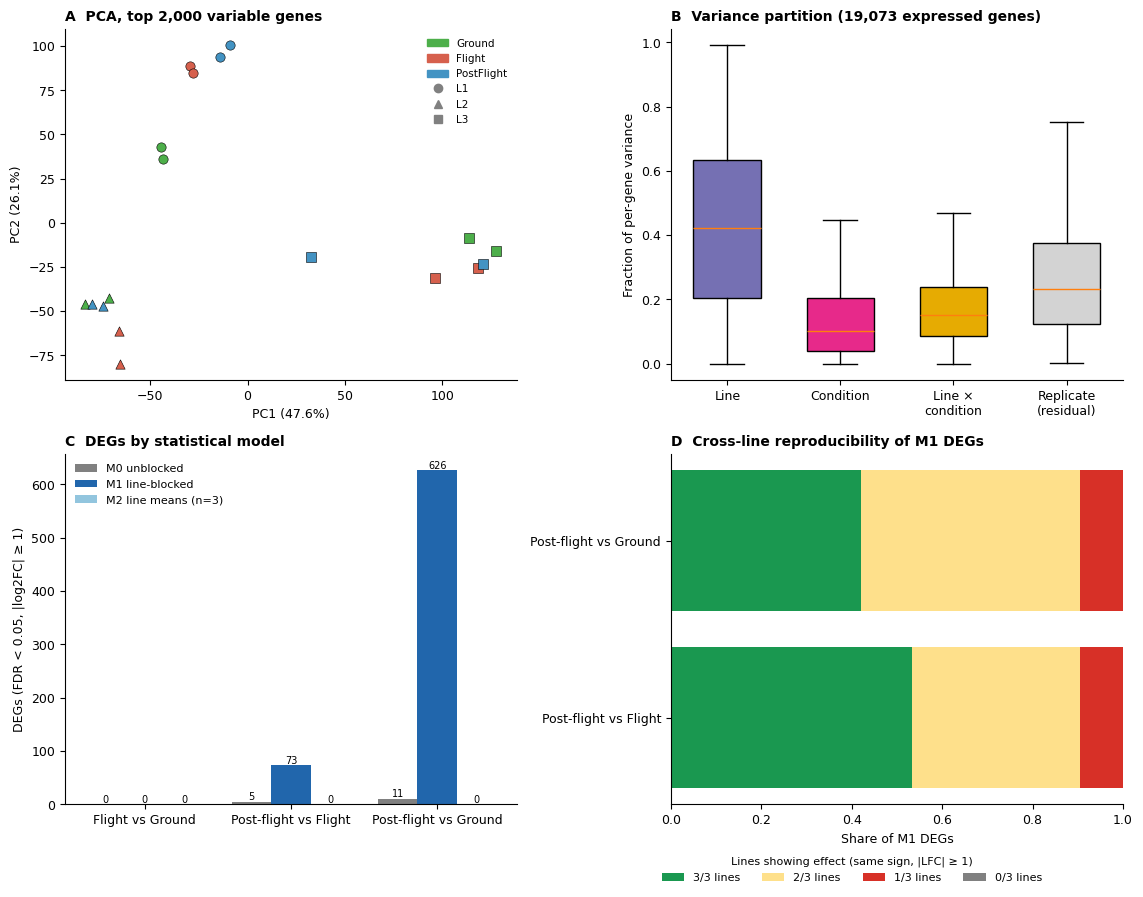

Saved FigSW1_outlier_assessment


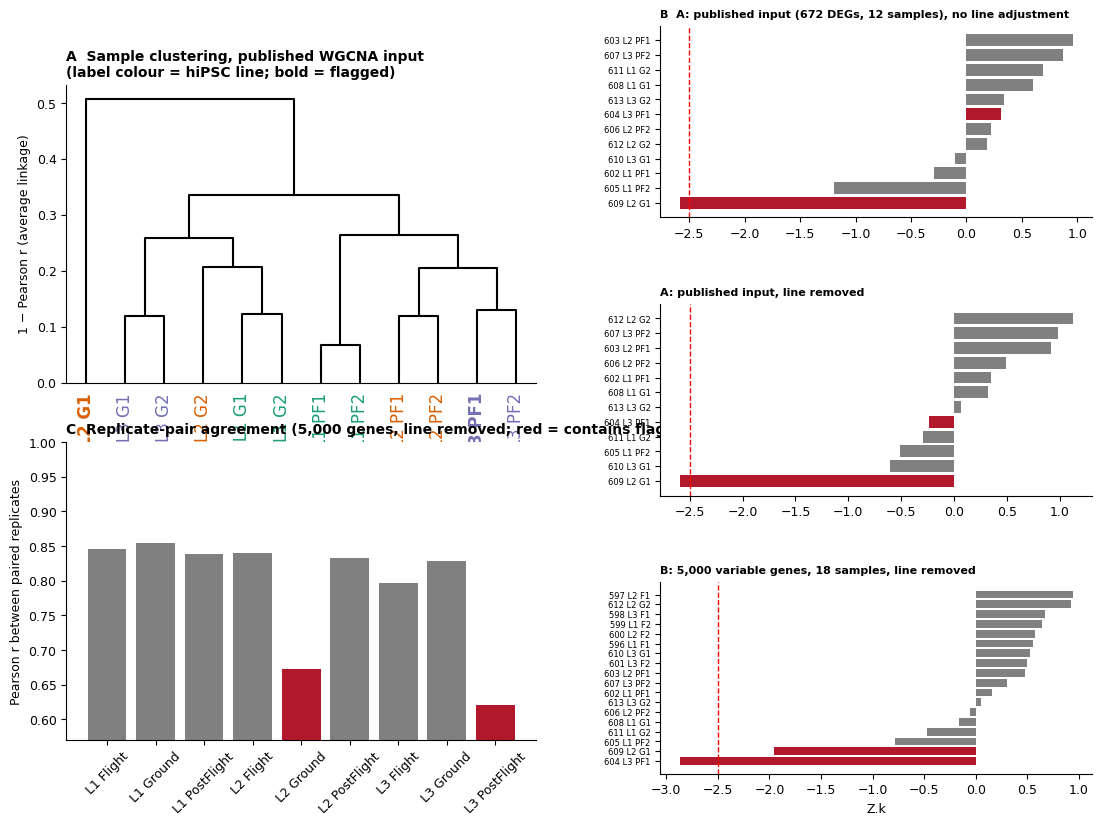

Saved FigSW2_stability_published_design


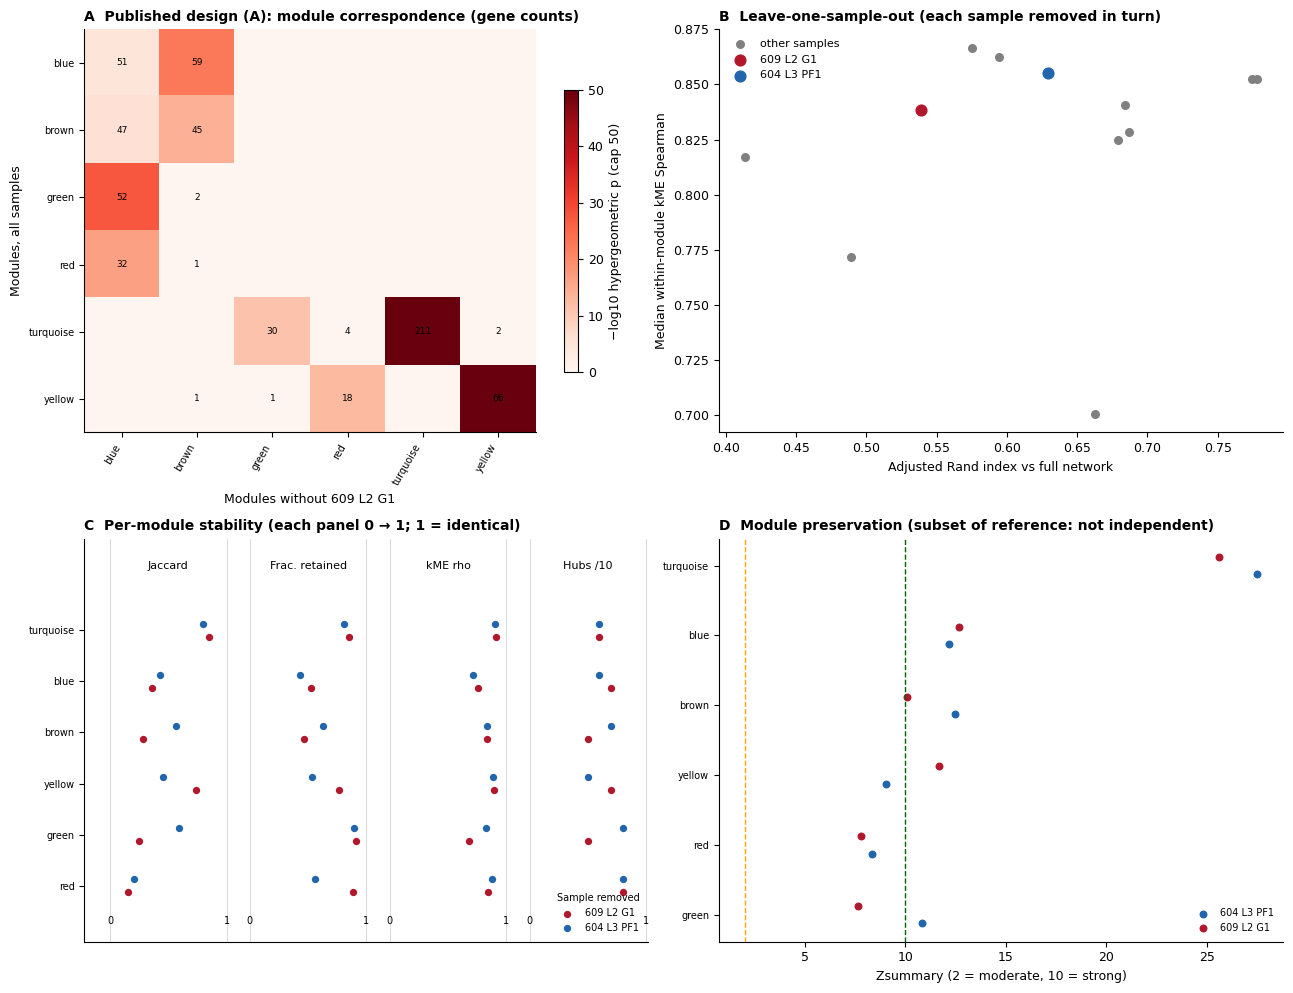

Saved FigSW3_stability_line_aware_design


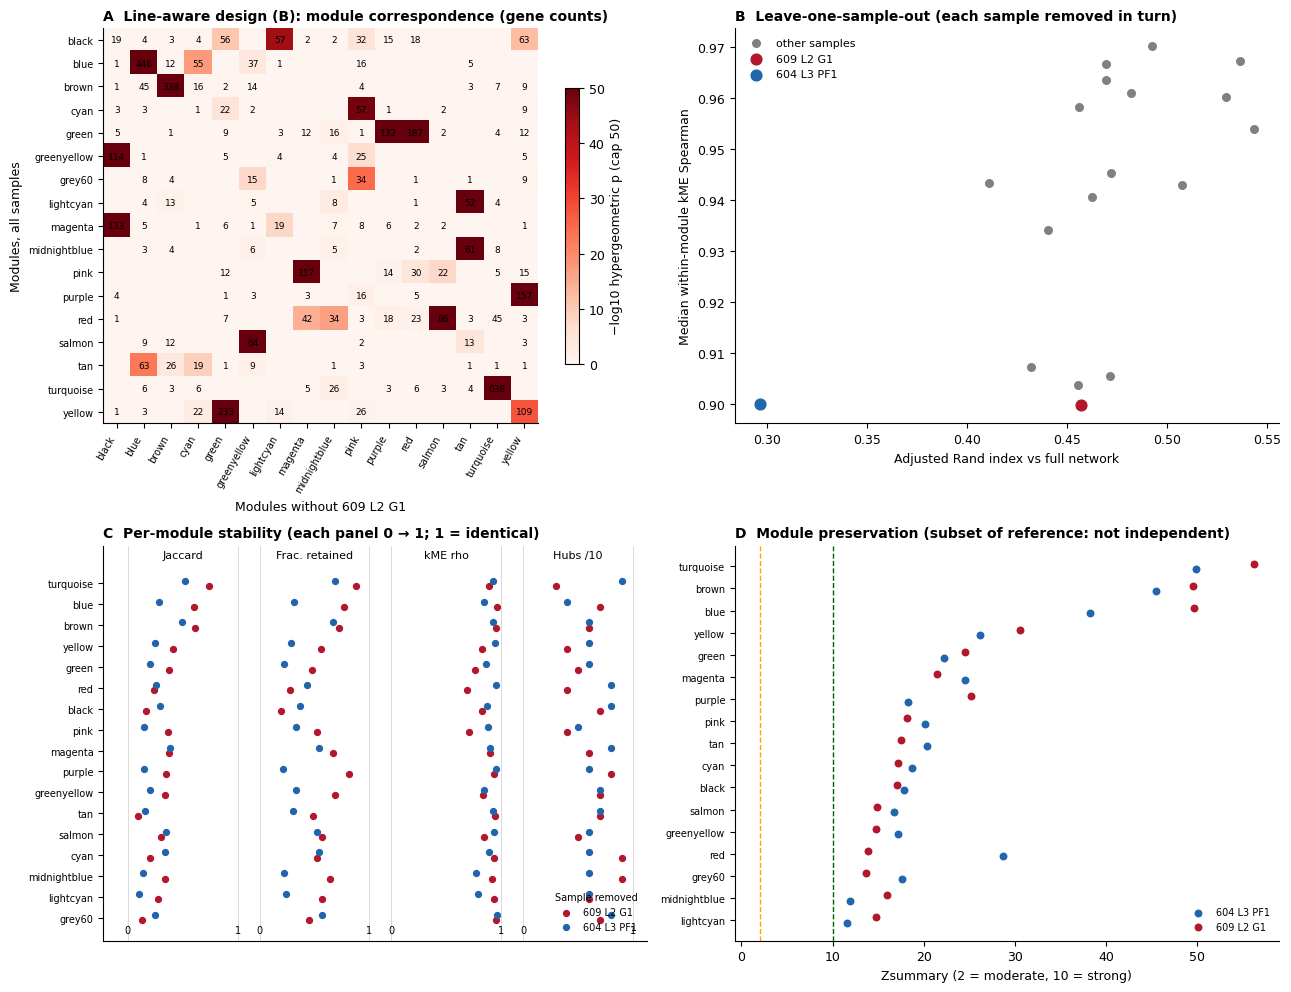

Saved FigSW4_signature_effects_heatmap


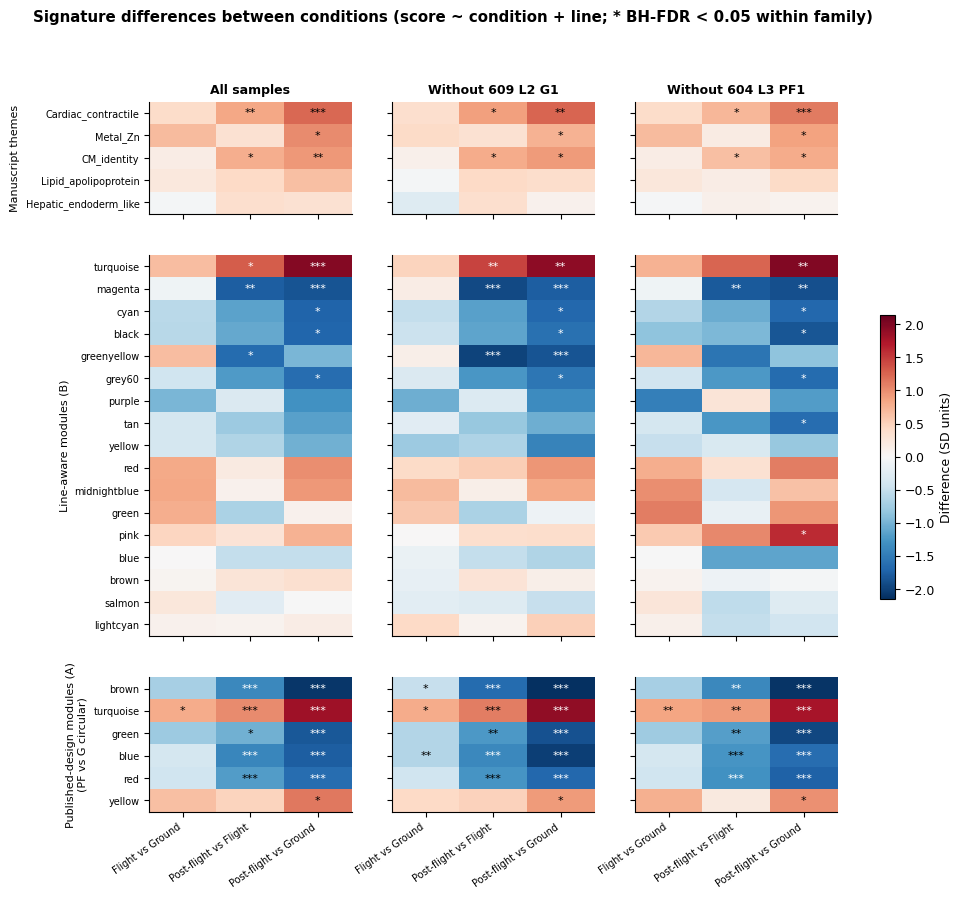

Saved FigSW5_signature_trajectories


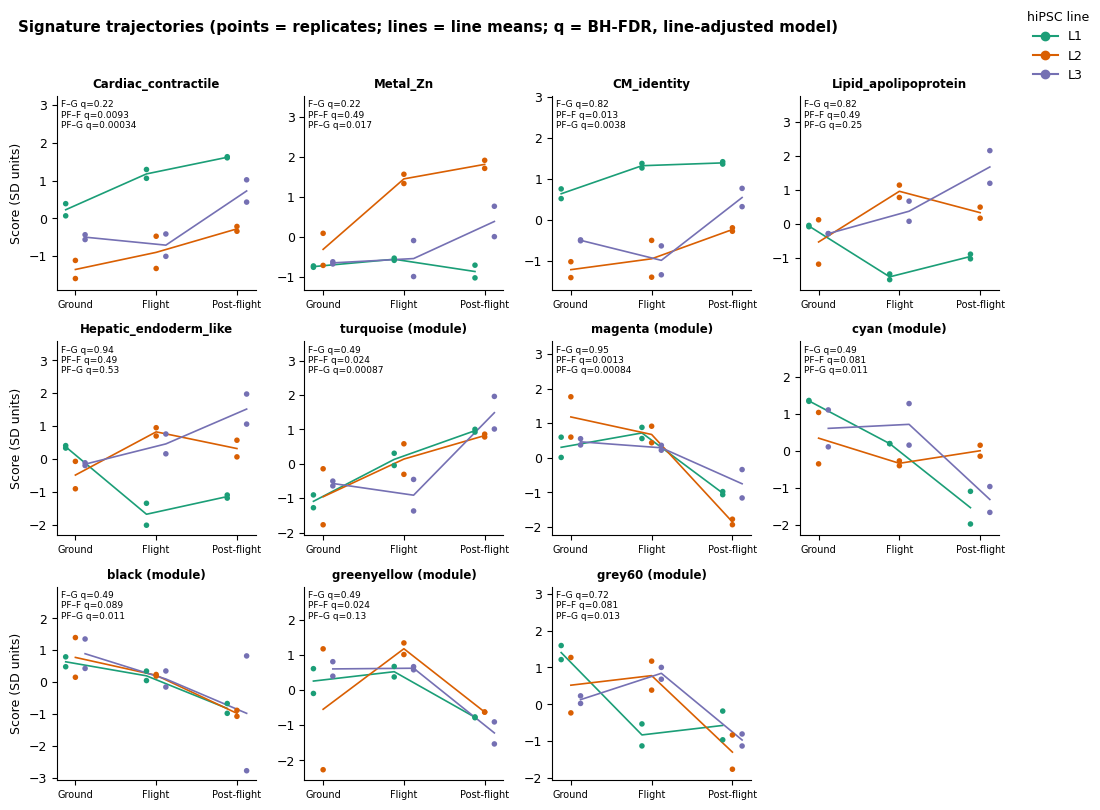

In [15]:
def save(fig, name):
    for ext in ["pdf", "svg", "png"]: fig.savefig(os.path.join(CFG["out"], "figures", f"{name}.{ext}"))
    print("Saved", name); plt.show(); plt.close(fig)
FLAG_COLS = ["#B2182B", "#2166AC", "#762A83"]

# ---- Figure 1: line structure and line-aware DE ----
fig, axs = plt.subplots(2, 2, figsize=(11.5, 9))
ax = axs[0, 0]
for c, col in COND_COLS.items():
    for l, mk in zip(["L1", "L2", "L3"], ["o", "^", "s"]):
        i = (meta.condition == c) & (meta.line == l)
        ax.scatter(pcs.loc[i, "PC1"], pcs.loc[i, "PC2"], c=col, marker=mk, s=45, edgecolors="k", linewidths=0.4)
ax.set_xlabel(f"PC1 ({ve[0]:.1f}%)"); ax.set_ylabel(f"PC2 ({ve[1]:.1f}%)"); ax.set_title("A  PCA, top 2,000 variable genes", loc="left")
ax.legend(handles=[Patch(color=v, label=k) for k, v in COND_COLS.items()] +
          [Line2D([0], [0], marker=m, ls="", color="grey", label=l) for l, m in zip(["L1", "L2", "L3"], ["o", "^", "s"])],
          frameon=False, fontsize=7.5, loc="best")
ax = axs[0, 1]
bp = ax.boxplot([vp[c].values for c in vp.columns], showfliers=False, patch_artist=True, widths=0.6)
for p, col in zip(bp["boxes"], ["#7570B3", "#E7298A", "#E6AB02", "lightgrey"]): p.set_facecolor(col)
ax.set_xticks([1, 2, 3, 4]); ax.set_xticklabels(["Line", "Condition", "Line ×\ncondition", "Replicate\n(residual)"])
ax.set_ylabel("Fraction of per-gene variance"); ax.set_title(f"B  Variance partition ({len(vp):,} expressed genes)", loc="left")
ax = axs[1, 0]
dc = de_counts.assign(n=de_counts.up + de_counts.down)
mlab = {"M0_unblocked": "M0 unblocked", "M1_line_blocked": "M1 line-blocked", "M2_line_mean": "M2 line means (n=3)"}
for j, (m, col) in enumerate(zip(mlab, ["grey", "#2166AC", "#92C5DE"])):
    d = dc[dc.model == m].set_index("contrast").reindex(["FG", "PFF", "PFG"])
    b = ax.bar(np.arange(3) + (j - 1) * 0.27, d.n, 0.27, color=col, label=mlab[m])
    ax.bar_label(b, fontsize=7)
ax.set_xticks(range(3)); ax.set_xticklabels([CLAB[k] for k in ["FG", "PFF", "PFG"]])
ax.set_ylabel("DEGs (FDR < 0.05, |log2FC| ≥ 1)"); ax.legend(frameon=False, fontsize=8); ax.set_title("C  DEGs by statistical model", loc="left")
ax = axs[1, 1]
cc = cons.reindex(columns=[3, 2, 1, 0], fill_value=0); cc = cc.div(cc.sum(axis=1), axis=0)
left = np.zeros(len(cc))
for k, col in zip([3, 2, 1, 0], ["#1A9850", "#FEE08B", "#D73027", "grey"]):
    ax.barh([CLAB[i] for i in cc.index], cc[k], left=left, color=col, label=f"{k}/3 lines"); left += cc[k].values
ax.set_xlabel("Share of M1 DEGs"); ax.legend(frameon=False, fontsize=8, title="Lines showing effect (same sign, |LFC| ≥ 1)", title_fontsize=8, loc="upper center", bbox_to_anchor=(0.4, -0.12), ncol=4)
ax.set_title("D  Cross-line reproducibility of M1 DEGs", loc="left")
fig.tight_layout(); save(fig, "Fig1_line_structure_and_DE_models")

FLAGC = {HL[s]: FLAG_COLS[i] for i, s in enumerate(SENS)}   # one colour per flagged sample, used in every panel

# ---- Figure S-W1: outlier assessment ----
from scipy.cluster.hierarchy import dendrogram, linkage as _lk
fig = plt.figure(figsize=(12, 8.5)); gs = fig.add_gridspec(2, 2, width_ratios=[1.25, 1])
ax = fig.add_subplot(gs[0, 0])
Xr = logx.loc[genes_A, samples_A]
dn = dendrogram(_lk(Xr.T.values, "average", metric="correlation"), labels=[meta.loc[s, "label"] for s in samples_A], ax=ax, color_threshold=0, above_threshold_color="k", leaf_rotation=90)
for t in ax.get_xticklabels():
    s = [k for k in samples_A if meta.loc[k, "label"] == t.get_text()][0]
    t.set_color(LINE_COLS[meta.loc[s, "line"]]); t.set_fontweight("bold" if s in SENS else "normal")
ax.set_ylabel("1 − Pearson r (average linkage)"); ax.set_title("A  Sample clustering, published WGCNA input\n(label colour = hiPSC line; bold = flagged)", loc="left")
ax = fig.add_subplot(gs[1, 0])
rc = rep_cor.assign(name=rep_cor.line + " " + rep_cor.condition, fl=rep_cor.s1.isin(SENS) | rep_cor.s2.isin(SENS))
ax.bar(rc.name, rc.r_line_adjusted_B, color=np.where(rc.fl, "#B2182B", "grey"))
ax.set_ylim(rc.r_line_adjusted_B.min() - 0.05, 1); ax.set_ylabel("Pearson r between paired replicates"); ax.tick_params(axis="x", rotation=45)
ax.set_title("C  Replicate-pair agreement (5,000 genes, line removed; red = contains flagged sample)", loc="left")
sub = fig.add_gridspec(3, 1, left=0.62, right=0.98, top=0.95, bottom=0.07, hspace=0.45)
for i, (sp, d) in enumerate(outl.groupby("space", sort=False)):
    ax = fig.add_subplot(sub[i]); d = d.sort_values("Zk")
    ax.barh(d.label, d.Zk, color=np.where(d["sample"].isin(SENS), "#B2182B", "grey")); ax.axvline(CFG["zk_threshold"], ls="--", c="red", lw=1)
    ax.tick_params(axis="y", labelsize=6); ax.set_title(("B  " if i == 0 else "") + sp, loc="left", fontsize=8); ax.set_xlabel("Z.k" if i == 2 else "")
save(fig, "FigSW1_outlier_assessment")

# ---- Figures S-W2 / S-W3: module stability ----
def stability_figure(drops, targeted, loo, pres, tag, name):
    fig, axs = plt.subplots(2, 2, figsize=(13, 10)); s0 = list(drops)[0]
    ct = drops[s0]["cmp"]["crosstab"]; ct = ct.drop(index="grey", columns="grey", errors="ignore")
    N = ct.values.sum(); P = np.zeros(ct.shape)
    for i, r in enumerate(ct.index):
        for j, c in enumerate(ct.columns):
            P[i, j] = -np.log10(max(stats.hypergeom.sf(ct.iloc[i, j] - 1, N, ct.loc[r].sum(), ct[c].sum()), 1e-300)) if ct.iloc[i, j] > 0 else 0
    ax = axs[0, 0]; im = ax.imshow(np.minimum(P, 50), cmap="Reds", aspect="auto", vmin=0, vmax=50)
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]):
            if ct.iloc[i, j] > 0: ax.text(j, i, ct.iloc[i, j], ha="center", va="center", fontsize=6.5)
    ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels(ct.columns, rotation=60, ha="right", fontsize=7)
    ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels(ct.index, fontsize=7)
    ax.set_xlabel(f"Modules without {HL[s0]}"); ax.set_ylabel("Modules, all samples")
    fig.colorbar(im, ax=ax, shrink=0.7, label="−log10 hypergeometric p (cap 50)"); ax.set_title(f"A  {tag}: module correspondence (gene counts)", loc="left")
    ax = axs[0, 1]; l2 = loo.assign(fl=loo.removed.isin(SENS))
    ax.scatter(l2.ARI[~l2.fl], l2.median_kME_rho[~l2.fl], c="grey", s=30, label="other samples")
    for s in [s for s in SENS if s in set(loo.removed)]:
        r = l2[l2.removed == s].iloc[0]; ax.scatter(r.ARI, r.median_kME_rho, c=FLAGC[HL[s]], s=60, label=HL[s], zorder=3)
    ax.set_xlabel("Adjusted Rand index vs full network"); ax.set_ylabel("Median within-module kME Spearman")
    ax.legend(frameon=False, fontsize=8); ax.set_title("B  Leave-one-sample-out (each sample removed in turn)", loc="left")
    ax = axs[1, 0]; mets = [("jaccard", "Jaccard"), ("frac_genes_retained", "Frac. retained"), ("kME_spearman", "kME rho"), ("hub_overlap_same_def", "Hubs /10")]
    mods = list(targeted.groupby("module")["size"].first().sort_values().index)
    for k, (col, lab) in enumerate(mets):
        for i, (rm, d) in enumerate(targeted.groupby("removed", sort=False)):
            v = d.set_index("module").reindex(mods)[col] / (10 if col.startswith("hub") else 1)
            ax.scatter(v + k * 1.2, np.arange(len(mods)) + (i - 0.5) * 0.25, c=FLAGC[rm], s=18, label=rm if k == 0 else None)
        ax.axvline(k * 1.2, c="lightgrey", lw=0.6); ax.axvline(k * 1.2 + 1, c="lightgrey", lw=0.6)
        ax.text(k * 1.2, -0.75, "0", ha="center", fontsize=7); ax.text(k * 1.2 + 1, -0.75, "1", ha="center", fontsize=7)
        ax.text(k * 1.2 + 0.5, len(mods) + 0.2, lab, ha="center", fontsize=8)
    ax.set_yticks(range(len(mods))); ax.set_yticklabels(mods, fontsize=7); ax.set_xticks([]); ax.set_ylim(-1.1, len(mods) + 0.8)
    ax.legend(frameon=False, fontsize=7, loc="lower right", title="Sample removed", title_fontsize=7)
    ax.set_title("C  Per-module stability (each panel 0 → 1; 1 = identical)", loc="left")
    ax = axs[1, 1]; pm = pres.pivot(index="module", columns="removed", values="Zsummary"); pm = pm.loc[pm.min(axis=1).sort_values().index]
    for i, c in enumerate(pm.columns): ax.scatter(pm[c], np.arange(len(pm)) + (i - 0.5) * 0.25, c=FLAGC[c], s=22, label=c)
    ax.axvline(2, ls="--", c="orange", lw=1); ax.axvline(10, ls="--", c="darkgreen", lw=1)
    ax.set_yticks(range(len(pm))); ax.set_yticklabels(pm.index, fontsize=7); ax.set_xlabel("Zsummary (2 = moderate, 10 = strong)")
    ax.legend(frameon=False, fontsize=7); ax.set_title("D  Module preservation (subset of reference: not independent)", loc="left")
    fig.tight_layout(); save(fig, name)
stability_figure(A_drop, A_targeted, A_loo, A_pres, "Published design (A)", "FigSW2_stability_published_design")
stability_figure(B_drop, B_targeted, B_loo, B_pres, "Line-aware design (B)", "FigSW3_stability_line_aware_design")

# ---- Figure S-W4: signature effect heatmap ----
order = sig_res[sig_res.analysis == "All samples"].groupby("signature").delta_SD.apply(lambda v: v.abs().max()).sort_values(ascending=False)
fams = [("T", "Manuscript themes"), ("B", "Line-aware modules (B)"), ("A", "Published-design modules (A)\n(PF vs G circular)")]
an = list(runs); lim = sig_res.delta_SD.abs().max()
heights = [sum(s.startswith(f) for s in order.index) for f, _ in fams]
fig, axs = plt.subplots(3, len(an), figsize=(3.2 * len(an) + 1.5, 0.24 * sum(heights) + 2.5), gridspec_kw=dict(height_ratios=heights), squeeze=False)
for i, (f, flab) in enumerate(fams):
    sigs = [s for s in order.index if s.startswith(f)]
    for j, a in enumerate(an):
        d = sig_res[(sig_res.analysis == a) & sig_res.signature.isin(sigs)]
        M = d.pivot(index="signature", columns="contrast", values="delta_SD").loc[sigs, list(CONTRASTS)]
        Q = d.pivot(index="signature", columns="contrast", values="FDR").loc[sigs, list(CONTRASTS)]
        ax = axs[i, j]; im = ax.imshow(M.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
        for r in range(M.shape[0]):
            for c in range(M.shape[1]):
                q = Q.iloc[r, c]; st = "***" if q < 0.001 else "**" if q < 0.01 else "*" if q < 0.05 else ""
                ax.text(c, r, st, ha="center", va="center", fontsize=8, color="white" if abs(M.iloc[r, c]) > 0.6 * lim else "black")
        ax.set_yticks(range(len(sigs))); ax.set_yticklabels([s[2:] for s in sigs] if j == 0 else [], fontsize=7)
        ax.set_xticks(range(3)); ax.set_xticklabels([CLAB[c] for c in CONTRASTS] if i == 2 else [], rotation=35, ha="right", fontsize=7)
        if i == 0: ax.set_title(a, fontsize=9)
        if j == 0: ax.set_ylabel(flab, fontsize=8)
fig.colorbar(im, ax=axs, shrink=0.4, label="Difference (SD units)")
fig.suptitle("Signature differences between conditions (score ~ condition + line; * BH-FDR < 0.05 within family)", fontweight="bold", x=0.02, ha="left")
save(fig, "FigSW4_signature_effects_heatmap")

# ---- Figure S-W5: signature trajectories by line ----
S_all = build_scores(list(meta.index))
minq = sig_res[sig_res.analysis == "All samples"].groupby("signature").FDR.min()
show = [s for s in order.index if s.startswith("T_")] + [s for s in order.index if s.startswith("B_") and minq[s] < 0.05][:7]
nc = 4; nr = int(np.ceil(len(show) / nc))
fig, axs = plt.subplots(nr, nc, figsize=(11, 2.7 * nr), squeeze=False)
for k, s in enumerate(show):
    ax = axs.flat[k]; y = (S_all[s] - S_all[s].mean()) / S_all[s].std(ddof=1)
    for li, (l, col) in enumerate(LINE_COLS.items()):
        xs, ms = [], []
        for ci, c in enumerate(CONDS):
            idx = meta.index[(meta.line == l) & (meta.condition == c)]
            ax.scatter([ci + (li - 1) * 0.12] * len(idx), y[idx], c=col, s=16, zorder=3, edgecolors="none")
            xs.append(ci + (li - 1) * 0.12); ms.append(y[idx].mean())
        ax.plot(xs, ms, c=col, lw=1.2)
    q = sig_res[(sig_res.analysis == "All samples") & (sig_res.signature == s)].set_index("contrast").FDR
    ax.text(0.02, 0.98, f"F–G q={q['FG']:.2g}\nPF–F q={q['PFF']:.2g}\nPF–G q={q['PFG']:.2g}", transform=ax.transAxes, va="top", fontsize=6.5)
    ax.set_xticks(range(3)); ax.set_xticklabels(["Ground", "Flight", "Post-flight"], fontsize=7)
    ax.set_title(s[2:] + (" (module)" if s.startswith("B_") else ""), fontsize=8.5); ax.set_ylim(y.min() - 0.3, y.max() + 1.6)
    if k % nc == 0: ax.set_ylabel("Score (SD units)")
for ax in axs.flat[len(show):]: ax.axis("off")
fig.legend([Line2D([0], [0], color=c, marker="o") for c in LINE_COLS.values()], list(LINE_COLS), title="hiPSC line", loc="upper right", frameon=False)
fig.suptitle("Signature trajectories (points = replicates; lines = line means; q = BH-FDR, line-adjusted model)", fontweight="bold", x=0.02, ha="left")
fig.tight_layout(rect=(0, 0, 0.93, 0.96)); save(fig, "FigSW5_signature_trajectories")

In [18]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats
from scipy.cluster.hierarchy import dendrogram, linkage as _lk

# Helper function to save a single independent figure in multiple formats at 300 DPI
def save_single(fig, name):
    fig.tight_layout()
    for ext in ["pdf", "svg", "png"]:
        path = os.path.join(CFG["out"], "figures", f"{name}.{ext}")
        fig.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Saved individual plot: {name}")
    plt.close(fig)

print("Generating and saving all sub-panel figures individually...")

# -------------------------------------------------------------------------
# FIG 1A: PCA Scores Scatter
# -------------------------------------------------------------------------
fig_1a, ax = plt.subplots(figsize=(6, 5))
for c, col in COND_COLS.items():
    for l, mk in zip(["L1", "L2", "L3"], ["o", "^", "s"]):
        i = (meta.condition == c) & (meta.line == l)
        ax.scatter(pcs.loc[i, "PC1"], pcs.loc[i, "PC2"], c=col, marker=mk, s=55, edgecolors="k", linewidths=0.4)
ax.set_xlabel(f"PC1 ({ve[0]:.1f}%)")
ax.set_ylabel(f"PC2 ({ve[1]:.1f}%)")
ax.set_title("PCA, top 2,000 variable genes")
ax.legend(handles=[Patch(color=v, label=k) for k, v in COND_COLS.items()] +
          [Line2D([0], [0], marker=m, ls="", color="grey", label=l) for l, m in zip(["L1", "L2", "L3"], ["o", "^", "s"])],
          frameon=False, fontsize=8, loc="best")
save_single(fig_1a, "Fig1A_PCA_scores")

# -------------------------------------------------------------------------
# FIG 1B: Variance Partition Boxplot
# -------------------------------------------------------------------------
fig_1b, ax = plt.subplots(figsize=(6, 5))
bp = ax.boxplot([vp[c].values for c in vp.columns], showfliers=False, patch_artist=True, widths=0.5)
for p, col in zip(bp["boxes"], ["#7570B3", "#E7298A", "#E6AB02", "lightgrey"]):
    p.set_facecolor(col)
ax.set_xticks([1, 2, 3, 4])
ax.set_xticklabels(["Line", "Condition", "Line ×\ncondition", "Replicate\n(residual)"])
ax.set_ylabel("Fraction of per-gene variance")
ax.set_title(f"Variance partition ({len(vp):,} expressed genes)")
save_single(fig_1b, "Fig1B_variance_partition")

# -------------------------------------------------------------------------
# FIG 1C: DEGs by model
# -------------------------------------------------------------------------
fig_1c, ax = plt.subplots(figsize=(6, 5))
dc = de_counts.assign(n=de_counts.up + de_counts.down)
mlab = {"M0_unblocked": "M0 unblocked", "M1_line_blocked": "M1 line-blocked", "M2_line_mean": "M2 line means (n=3)"}
for j, (m, col) in enumerate(zip(mlab, ["grey", "#2166AC", "#92C5DE"])):
    d = dc[dc.model == m].set_index("contrast").reindex(["FG", "PFF", "PFG"])
    b = ax.bar(np.arange(3) + (j - 1) * 0.25, d.n, 0.25, color=col, label=mlab[m])
    ax.bar_label(b, fontsize=7)
ax.set_xticks(range(3))
ax.set_xticklabels([CLAB[k] for k in ["FG", "PFF", "PFG"]])
ax.set_ylabel("DEGs (FDR < 0.05, |log2FC| ≥ 1)")
ax.legend(frameon=False, fontsize=8)
ax.set_title("DEGs by statistical model")
save_single(fig_1c, "Fig1C_DEGs_by_model")

# -------------------------------------------------------------------------
# FIG 1D: DEG consistency horizontal bar
# -------------------------------------------------------------------------
fig_1d, ax = plt.subplots(figsize=(6.5, 4.5))
cc = cons.reindex(columns=[3, 2, 1, 0], fill_value=0)
cc = cc.div(cc.sum(axis=1), axis=0)
left = np.zeros(len(cc))
for k, col in zip([3, 2, 1, 0], ["#1A9850", "#FEE08B", "#D73027", "grey"]):
    ax.barh([CLAB[i] for i in cc.index], cc[k], left=left, color=col, label=f"{k}/3 lines")
    left += cc[k].values
ax.set_xlabel("Share of M1 DEGs")
ax.legend(frameon=False, fontsize=8, title="Lines showing effect (same sign, |LFC| ≥ 1)", title_fontsize=8, loc="lower center", bbox_to_anchor=(0.5, -0.28), ncol=4)
ax.set_title("Cross-line reproducibility of M1 DEGs")
save_single(fig_1d, "Fig1D_DEG_consistency")

# -------------------------------------------------------------------------
# FIG SW1A: Dendrogram
# -------------------------------------------------------------------------
fig_sw1a, ax = plt.subplots(figsize=(6.5, 5.5))
Xr = logx.loc[genes_A, samples_A]
dn = dendrogram(_lk(Xr.T.values, "average", metric="correlation"), labels=[meta.loc[s, "label" ] for s in samples_A], ax=ax, color_threshold=0, above_threshold_color="k", leaf_rotation=90)
for t in ax.get_xticklabels():
    s = [k for k in samples_A if meta.loc[k, "label"] == t.get_text()][0]
    t.set_color(LINE_COLS[meta.loc[s, "line"]])
    t.set_fontweight("bold" if s in SENS else "normal")
ax.set_ylabel("1 − Pearson r (average linkage)")
ax.set_title("Sample clustering, published WGCNA input")
save_single(fig_sw1a, "FigSW1A_dendrogram")

# -------------------------------------------------------------------------
# FIG SW1C: Replicate pair correlation
# -------------------------------------------------------------------------
fig_sw1c, ax = plt.subplots(figsize=(6.5, 4.5))
rc = rep_cor.assign(name=rep_cor.line + " " + rep_cor.condition, fl=rep_cor.s1.isin(SENS) | rep_cor.s2.isin(SENS))
ax.bar(rc.name, rc.r_line_adjusted_B, color=np.where(rc.fl, "#B2182B", "grey"))
ax.set_ylim(rc.r_line_adjusted_B.min() - 0.05, 1)
ax.set_ylabel("Pearson r between paired replicates")
ax.tick_params(axis="x", rotation=45)
ax.set_title("Replicate-pair agreement (5,000 genes, line removed)")
save_single(fig_sw1c, "FigSW1C_replicate_pair_correlation")

# -------------------------------------------------------------------------
# FIG SW1B: Outlier Zk scores (3 spaces separately)
# -------------------------------------------------------------------------
for i, (sp, d) in enumerate(outl.groupby("space", sort=False)):
    fig_zk, ax = plt.subplots(figsize=(5.5, 4))
    d = d.sort_values("Zk")
    ax.barh(d.label, d.Zk, color=np.where(d["sample"].isin(SENS), "#B2182B", "grey"))
    ax.axvline(CFG["zk_threshold"], ls="--", c="red", lw=1)
    ax.tick_params(axis="y", labelsize=7.5)
    ax.set_xlabel("Z.k")
    ax.set_title(sp.replace(", line removed", "\nline removed"), fontsize=8.5)
    clean_name = sp.replace(":", "").replace(",", "").replace(" ", "_").replace("(", "").replace(")", "").replace("=", "_").replace("−", "")
    save_single(fig_zk, f"FigSW1B_Zk_{clean_name[:40]}")

# -------------------------------------------------------------------------
# FIG SW5: Individual trajectory plots
# -------------------------------------------------------------------------
for k, s in enumerate(show):
    fig_traj, ax = plt.subplots(figsize=(4, 3.5))
    y = (S_all[s] - S_all[s].mean()) / S_all[s].std(ddof=1)
    for li, (l, col) in enumerate(LINE_COLS.items()):
        xs, ms = [], []
        for ci, c in enumerate(CONDS):
            idx = meta.index[(meta.line == l) & (meta.condition == c)]
            ax.scatter([ci + (li - 1) * 0.12] * len(idx), y[idx], c=col, s=20, zorder=3, edgecolors="none")
            xs.append(ci + (li - 1) * 0.12)
            ms.append(y[idx].mean())
        ax.plot(xs, ms, c=col, lw=1.2)
    q = sig_res[(sig_res.analysis == "All samples") & (sig_res.signature == s)].set_index("contrast").FDR
    ax.text(0.02, 0.98, f"F–G q={q['FG']:.2g}\nPF–F q={q['PFF']:.2g}\nPF–G q={q['PFG']:.2g}", transform=ax.transAxes, va="top", fontsize=7)
    ax.set_xticks(range(3))
    ax.set_xticklabels(["Ground", "Flight", "Post-flight"], fontsize=8)
    ax.set_title(s[2:] + (" (module)" if s.startswith("B_") else ""), fontsize=9.5)
    ax.set_ylabel("Score (SD units)")
    save_single(fig_traj, f"FigSW5_trajectory_{s}")

print("All individual paper-ready figure sub-panels saved successfully!")

Generating and saving all sub-panel figures individually...
Saved individual plot: Fig1A_PCA_scores
Saved individual plot: Fig1B_variance_partition
Saved individual plot: Fig1C_DEGs_by_model
Saved individual plot: Fig1D_DEG_consistency
Saved individual plot: FigSW1A_dendrogram
Saved individual plot: FigSW1C_replicate_pair_correlation
Saved individual plot: FigSW1B_Zk_A_published_input_672_DEGs_12_samples_no
Saved individual plot: FigSW1B_Zk_A_published_input_line_removed
Saved individual plot: FigSW1B_Zk_B_5000_variable_genes_18_samples_line_re
Saved individual plot: FigSW5_trajectory_T_Cardiac_contractile
Saved individual plot: FigSW5_trajectory_T_Metal_Zn
Saved individual plot: FigSW5_trajectory_T_CM_identity
Saved individual plot: FigSW5_trajectory_T_Lipid_apolipoprotein
Saved individual plot: FigSW5_trajectory_T_Hepatic_endoderm_like
Saved individual plot: FigSW5_trajectory_B_turquoise
Saved individual plot: FigSW5_trajectory_B_magenta
Saved individual plot: FigSW5_trajectory_B_cya

## 11. Export and computed summary
The summary text is generated from the results. Nothing is hard-coded.

In [16]:
with pd.ExcelWriter(tab("SUMMARY_reviewer_WGCNA_signatures.xlsx")) as xw:
    for n, d in dict(pc_association=pc_assoc, DEG_list_audit=audit, DEG_counts=de_counts, M1_consistency=cons.reset_index(), outlier_Zk=outl, replicate_cor=rep_cor, A_modules=A_modtab, A_targeted=A_targeted, A_LOO=A_loo,
                     A_params=A_param, A_preservation=A_pres, B_modules=B_modtab, B_targeted=B_targeted, B_LOO=B_loo,
                     B_preservation=B_pres, signature_tests=sig_res, signature_patterns=sig_class,
                     pattern_stability=pattern_stability.reset_index()).items():
        d.to_excel(xw, sheet_name=n[:31], index=False)

def loo_line(loo, s):
    if s not in set(loo.removed): return "not in this sample set"
    r = loo[loo.removed == s].iloc[0]
    return (f"ARI {r.ARI:.2f} (rank {r.rank_ARI_1_least_stable} of {len(loo)}, 1 = most disruptive; median over all removals {loo.ARI.median():.2f}); "
            f"median kME rho {r.median_kME_rho:.2f}; mean hub overlap {r.mean_hub_overlap:.1f}/10")
lines = [f"Line vs condition: PC1 R2(line) = {pc_assoc.R2_line[0]:.2f}, R2(condition) = {pc_assoc.R2_condition[0]:.2f}; median variance fraction line {vp.line.median():.2f}, condition {vp.condition.median():.2f}",
         "DEGs (FDR<0.05, |LFC|>=1) by model: " + "; ".join(f"{r.model}/{r.contrast}: {r.up + r.down}" for r in de_counts.itertuples()),
         f"Flagged or reviewer-named samples: {', '.join(HL.values())}",
         f"Z.k of {CFG['reviewer_sample']}: " + "; ".join(f"{sp.split(':')[0]}: {z:.2f}" for sp, z in outl[outl['sample'] == CFG['reviewer_sample']][['space', 'Zk']].values),
         f"[A] published design: power {pA}, {len(A_modtab)} modules; ARI vs published S3 = {s3_ari:.3f}",
         *[f"    without {HL[s]}: {loo_line(A_loo, s)}" for s in SENS],
         f"    leave-one-out ARI range over all samples: {A_loo.ARI.min():.2f}-{A_loo.ARI.max():.2f}; parameter-sensitivity ARI range: {A_param.ARI_vs_primary.min():.2f}-{A_param.ARI_vs_primary.max():.2f}",
         f"    Zsummary range after removal: {A_pres.Zsummary.min():.1f}-{A_pres.Zsummary.max():.1f}; modules with Z<2: {int((A_pres.Zsummary < 2).sum())}",
         *[f"    {r.module}: r(PF) full {r.r_PF_full:+.2f} -> reduced {r.r_PF_reduced:+.2f} (without {r.removed})" for r in A_targeted.itertuples()],
         f"[B] line-aware design: power {pB}, {len(B_modtab)} modules",
         *[f"    without {HL[s]}: {loo_line(B_loo, s)}" for s in SENS],
         f"    leave-one-out ARI range: {B_loo.ARI.min():.2f}-{B_loo.ARI.max():.2f}; Zsummary range: {B_pres.Zsummary.min():.1f}-{B_pres.Zsummary.max():.1f}",
         "[Comment 2] trajectory patterns (all samples):",
         *[f"    {r.signature}: {r.pattern}" for r in sig_class[sig_class.analysis == "All samples"].itertuples()],
         f"    pattern calls changing when a flagged sample is removed: {int(pattern_stability.changes_with_removal.sum())} of {len(pattern_stability)}"]
open(os.path.join(CFG["out"], "SUMMARY.txt"), "w").write("\n".join(lines)); print("\n".join(lines))
import platform; open(os.path.join(CFG["out"], "environment.txt"), "w").write(
    f"python {platform.python_version()}\nnumpy {np.__version__}\npandas {pd.__version__}\nscipy {__import__('scipy').__version__}\nmatplotlib {matplotlib.__version__}\n")
print("\nAll outputs in:", CFG["out"])

# ---- zip everything for one-click download ----
import shutil
zip_path = shutil.make_archive(CFG["out"], "zip", CFG["out"])
print("Zipped results:", zip_path)
if IN_COLAB:
    try:
        from google.colab import files as _f; _f.download(zip_path)
    except Exception as e: print("(Automatic download unavailable; get the zip from the file browser.)", e)

Line vs condition: PC1 R2(line) = 0.93, R2(condition) = 0.00; median variance fraction line 0.42, condition 0.10
DEGs (FDR<0.05, |LFC|>=1) by model: M0_unblocked/FG: 0; M0_unblocked/PFF: 5; M0_unblocked/PFG: 11; M1_line_blocked/FG: 0; M1_line_blocked/PFF: 73; M1_line_blocked/PFG: 626; M2_line_mean/FG: 0; M2_line_mean/PFF: 0; M2_line_mean/PFG: 0
Flagged or reviewer-named samples: 609 L2 G1, 604 L3 PF1
Z.k of GSM4066609: A: -2.58; A: -2.59; B: -1.95
[A] published design: power 14, 6 modules; ARI vs published S3 = 0.749
    without 609 L2 G1: ARI 0.54 (rank 3 of 12, 1 = most disruptive; median over all removals 0.65); median kME rho 0.84; mean hub overlap 6.3/10
    without 604 L3 PF1: ARI 0.63 (rank 6 of 12, 1 = most disruptive; median over all removals 0.65); median kME rho 0.86; mean hub overlap 6.7/10
    leave-one-out ARI range over all samples: 0.41-0.78; parameter-sensitivity ARI range: 0.55-1.00
    Zsummary range after removal: 7.6-27.5; modules with Z<2: 0
    red: r(PF) full -0

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>